# AI Product Description Generator
### A practical workflow for creating clearer, consistent product listings

**Abhishek Tiwari - 1338220 · Biren Gohel - 1317182**

This notebook implements every part of the research presentation, slide by slide, and extends it to four generation modes:

| Mode | Input | Output |
|---|---|---|
| **Text → Text** | product facts | title, description, bullets, meta description, review flags |
| **Text → Image** | product facts + style | product visual |
| **Image → Text** | product photo (+ optional facts) | reviewable listing draft |
| **Image → Image** | product photo + style | restyled storefront image |

**Contents (mapped to the slides)**

| § | Slide | Topic |
|---|---|---|
| 0 | – | Setup, API keys and settings |
| 1 | 2 | The design choice: generate a draft from seller facts |
| 2 | 3 | The catalog writing problem |
| 3 | 4 | Why this project was selected |
| 4 | 5 | End-to-end workflow |
| 5 | 6 | Inputs and outputs (data model) |
| 6 | 7 | System architecture |
| 7 | 8 | What happens during one request: validate → normalize |
| 8 | 9 | Prompt and output methodology: build prompt → check response |
| 9 | 15 | Guardrail: unsupported-claim checker |
| 10 | 10 | Interface & implementation: images, provider adapters, exports |
| 11 | 12 | The four modes in action (incl. the slide-12 example) |
| 12 | 7/10 | MongoDB storage |
| 13 | 13 | Evaluation |
| 14 | 14 | Source claims vs. evidence |
| 15 | 15 | Limitations and safeguards (demonstrated) |
| 16 | 11 | Five-day build plan |
| 17 | 16 | Next steps: batch generation + conclusion |
| 18 | 17 | References |
| 19 | – | Using the running web app's REST API |

> Runs **fully offline** with the built-in template provider. Add an `OPENAI_API_KEY` or `GEMINI_API_KEY` to use a real model.

## 0 · Setup

Install the dependencies once (uncomment if needed). MongoDB is optional here: if no server is running at `MONGO_URI`, an in-memory `mongomock` database is used automatically.

In [1]:
# %pip install -q pydantic httpx pillow pymongo mongomock pandas matplotlib python-dotenv

**API keys stay out of source control (slide 7).** Put them in a `.env` file next to the project or set environment variables.
Leave them empty to use the offline provider.

In [2]:
import os
# Optional: paste keys here for this session only - never commit them.
# from getpass import getpass
# os.environ["OPENAI_API_KEY"] = getpass("OpenAI key (blank to skip): ")
# os.environ["GEMINI_API_KEY"] = getpass("Gemini key (blank to skip): ")

import base64, collections, csv, html, io, json, math, re, time, types, datetime as dt
from typing import Any, Callable, Dict, List, Optional, Tuple

import httpx
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display, Markdown, Image as IPImage
from pydantic import BaseModel, Field, ValidationError

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
"""Server-side settings (slide 7: keep provider credentials out of the browser and source control).

All values come from environment variables or a local `.env` file that is never committed.
"""

import os
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional

try:  # optional: load .env when python-dotenv is installed
    from dotenv import load_dotenv

    load_dotenv(Path(__file__).resolve().parent.parent / ".env")
except Exception:  # pragma: no cover
    pass


def _bool(name: str, default: bool) -> bool:
    return os.getenv(name, str(default)).strip().lower() in {"1", "true", "yes", "on"}


@dataclass
class Settings:
    # Which provider to use when the request says "auto": mock | openai | gemini
    default_provider: str = os.getenv("DEFAULT_PROVIDER", "auto")

    openai_api_key: str = os.getenv("OPENAI_API_KEY", "")
    openai_text_model: str = os.getenv("OPENAI_TEXT_MODEL", "gpt-4o-mini")
    openai_image_model: str = os.getenv("OPENAI_IMAGE_MODEL", "gpt-image-2")

    gemini_api_key: str = os.getenv("GEMINI_API_KEY", "")
    gemini_text_model: str = os.getenv("GEMINI_TEXT_MODEL", "gemini-3.5-flash")
    gemini_image_model: str = os.getenv("GEMINI_IMAGE_MODEL", "gemini-nano-banana-2.1")

    # Slide 8: timeout + bounded retry policy
    request_timeout_s: float = float(os.getenv("REQUEST_TIMEOUT_S", "60"))
    max_retries: int = int(os.getenv("MAX_RETRIES", "2"))

    # Slide 7/10: request limits
    rate_limit_per_minute: int = int(os.getenv("RATE_LIMIT_PER_MINUTE", "30"))
    max_image_mb: float = float(os.getenv("MAX_IMAGE_MB", "8"))

    # MongoDB
    mongo_uri: str = os.getenv("MONGO_URI", "mongodb://localhost:27017")
    mongo_db: str = os.getenv("MONGO_DB", "product_copy_ai")
    # If MongoDB is unreachable, fall back to an in-memory mock so the app still runs.
    allow_memory_fallback: bool = _bool("ALLOW_MEMORY_FALLBACK", True)

    # Slide 15: product data can be sensitive -> minimise retained data
    store_inputs: bool = _bool("STORE_INPUTS", True)

    allowed_origins: list = field(
        default_factory=lambda: [o.strip() for o in os.getenv("ALLOWED_ORIGINS", "*").split(",") if o.strip()]
    )

    def resolve_provider(self, requested: Optional[str]) -> str:
        """Pick the provider for one request. 'auto' prefers a configured real provider."""
        p = (requested or "auto").lower()
        if p == "auto":  # the request left it open: use the server's DEFAULT_PROVIDER setting
            p = (self.default_provider or "auto").lower()
        if p == "auto":
            if self.openai_api_key:
                return "openai"
            if self.gemini_api_key:
                return "gemini"
            return "mock"
        return p

    def available_providers(self) -> dict:
        return {
            "mock": True,
            "openai": bool(self.openai_api_key),
            "gemini": bool(self.gemini_api_key),
        }


settings = Settings()


print("Provider used for 'auto':", settings.resolve_provider(None))
print("Configured providers   :", settings.available_providers())

Provider used for 'auto': mock
Configured providers   : {'mock': True, 'openai': False, 'gemini': False}


## 1 · The design choice (slide 2)

> **Generate a draft from facts the seller provides.**

* A form collects a product name, category, features, audience, tone and an optional search phrase.
* Python checks the entries, builds instructions and a response schema, then calls the selected language model.
* The app returns separate fields - title, description, bullets and suggested metadata - so a seller can edit and export them.

The first version sends the facts with each request. It does **not** train a model or search a catalog database.

## 2 · The catalog writing problem (slide 3)
A product listing has to be both informative and easy to scan.

In [4]:
problem = pd.DataFrame({
    "What sellers have": ["Raw attributes and notes", "Different writing styles across SKUs",
                          "Repeated manual drafting", "Search terms may be overlooked"],
    "What customers need": ["A quick sense of fit and use", "Consistent voice across a range",
                            "Fast updates when products change", "Clear titles and descriptions"],
})
display(problem)
display(Markdown("**Human cost:** a wrong material, size, compatibility statement, or performance claim can mislead a buyer. "
                 "*Automation should remove blank-page work, not remove responsibility.*"))

,What sellers have,What customers need
0,Raw attributes and notes,A quick sense of fit and use
1,Different writing styles across SKUs,Consistent voice across a range
2,Repeated manual drafting,Fast updates when products change
3,Search terms may be overlooked,Clear titles and descriptions


**Human cost:** a wrong material, size, compatibility statement, or performance claim can mislead a buyer. *Automation should remove blank-page work, not remove responsibility.*

## 3 · Why this project was selected (slide 4)
The original deck compared four ideas on build effort and infrastructure.

,Project idea,Effort,Main infrastructure,Source estimate,Midpoint (weeks)
0,Product description generator,Very low,LLM API,3–5 days,0.6
1,Healthcare chatbot with RAG,High,Embeddings + vector DB,3–4 weeks,3.5
2,3D model generator,Very high,GPU + custom models,8–12 weeks,10.0
3,Autonomous code agent,High,Sandbox + agent tools,4–6 weeks,5.0


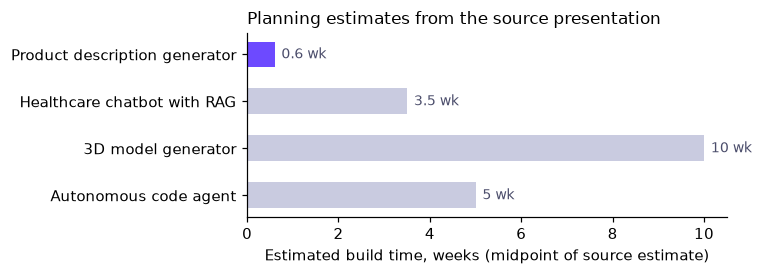

In [5]:
ideas = pd.DataFrame([
    ["Product description generator", "Very low", "LLM API", "3–5 days", 0.6],
    ["Healthcare chatbot with RAG", "High", "Embeddings + vector DB", "3–4 weeks", 3.5],
    ["3D model generator", "Very high", "GPU + custom models", "8–12 weeks", 10],
    ["Autonomous code agent", "High", "Sandbox + agent tools", "4–6 weeks", 5],
], columns=["Project idea", "Effort", "Main infrastructure", "Source estimate", "Midpoint (weeks)"])
display(ideas)

fig, ax = plt.subplots(figsize=(7, 2.6))
colors = ["#6d4aff" if i == 0 else "#c9cbe0" for i in range(len(ideas))]
ax.barh(ideas["Project idea"], ideas["Midpoint (weeks)"], color=colors, height=0.55)
for y, v in enumerate(ideas["Midpoint (weeks)"]):
    ax.text(v + 0.15, y, f"{v:g} wk", va="center", fontsize=9, color="#4b4d6b")
ax.invert_yaxis(); ax.set_xlabel("Estimated build time, weeks (midpoint of source estimate)")
ax.set_title("Planning estimates from the source presentation", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

The generator ranked well because its first version needs a narrow input-to-output flow and a model API, rather than custom training or specialized compute.

## 4 · End-to-end workflow (slide 5)

The seller stays in control at every point where facts or wording can change.

```
 1 Enter facts  ─►  2 Choose style  ─►  3 Generate  ─►  4 Review  ─►  5 Export
 name, category,    brand voice,         prompt = facts    compare every    copy or export
 materials,         keyword,             + rules + schema  claim with       plain / HTML /
 features,          destination format   + model request   product data     JSON / CSV
 audience
```

A generated draft is a **starting point**. A person checks accuracy, edits the copy, then approves the final listing.

## 5 · Inputs and outputs (slide 6)
The data model. Only name and category are required - optional fields stay optional and missing facts are never guessed.

In [6]:
"""Data shapes for inputs and outputs (slides 6 and 9).

Note: Optional/List are used instead of `X | None` so this runs on Python 3.9.
"""
from typing import List, Optional

from pydantic import BaseModel, Field

TONES = ["professional", "playful", "luxury", "minimal", "clear and practical"]
OUTPUT_FORMATS = ["plain", "html", "json", "csv"]
PROVIDERS = ["auto", "mock", "openai", "gemini"]
MODES = ["text-to-text", "text-to-image", "image-to-text", "image-to-image"]

IMAGE_STYLES = {
    "studio_white": "Clean e-commerce studio shot on a pure white background, soft shadow, centred, high detail",
    "lifestyle": "Natural lifestyle scene showing the product in everyday use, soft daylight, shallow depth of field",
    "luxury_dark": "Premium dark backdrop with dramatic rim lighting and subtle reflections",
    "minimal_pastel": "Minimal flat-lay on a soft pastel background with generous negative space",
    "vibrant_pop": "Bold colourful background, punchy contrast, playful social-media style",
}


class ProductFacts(BaseModel):
    """Everything the seller types in. Only name and category are required (slide 6 guardrail)."""

    product_name: str = Field("", description="Names the item")
    category: str = Field("", description="Sets the product context")
    materials: str = ""
    size: str = Field("", description="Dimensions, capacity or weight")
    features: List[str] = Field(default_factory=list)
    target_audience: str = ""
    use_case: str = ""
    brand_voice: str = "professional"
    brand_voice_id: Optional[str] = None  # a saved voice from the voices collection
    keyword: str = ""
    output_format: str = "plain"
    extra_notes: str = ""
    provider: str = "auto"


class ListingDraft(BaseModel):
    """The response shape from slide 9."""

    title: str
    description: str
    bullets: List[str]
    meta_description: str
    review_flags: List[str] = Field(default_factory=list)


class TextToImageRequest(BaseModel):
    facts: ProductFacts
    style: str = "studio_white"
    extra_prompt: str = ""


class ReviewRequest(BaseModel):
    """Human review step (slides 5, 10, 13)."""

    approved: bool = False
    edited: Optional[ListingDraft] = None
    rating: Optional[int] = Field(None, ge=1, le=5)
    unsupported_claims: int = Field(0, ge=0)
    total_claims: int = Field(0, ge=0)
    seconds_to_approve: Optional[float] = Field(None, ge=0)
    notes: str = ""


class ExportRequest(BaseModel):
    draft: ListingDraft
    format: str = "plain"
    product_name: str = ""


class BrandVoice(BaseModel):
    """Saved brand voice rules (slide 15 safeguard, slide 16 next step)."""

    name: str = Field(..., min_length=1, max_length=60)
    base_tone: str = "professional"
    rules: str = Field("", max_length=1500)
    example: str = Field("", max_length=1500)

In [7]:
io_table = pd.DataFrame([
    ["Product name + category", "Names the item and sets the product context", "Title and short heading"],
    ["Materials, size, features", "Provides facts the copy can safely use", "Description and feature bullets"],
    ["Target audience / use", "Helps explain relevance without inventing specs", "Use-focused benefit framing"],
    ["Brand voice", "Guides style while facts remain unchanged", "Professional, playful, luxury, or minimal copy"],
    ["Target keyword", "Optional phrase to include naturally", "Suggested title / meta description"],
    ["Output format", "Matches the seller's next step", "Plain text, HTML, JSON, or CSV"],
], columns=["Input from seller", "Why it matters", "Possible generated output"])
display(io_table)
print("Tones:", TONES); print("Formats:", OUTPUT_FORMATS); print("Image styles:", list(IMAGE_STYLES))

,Input from seller,Why it matters,Possible generated output
0,Product name + category,Names the item and sets the product context,Title and short heading
1,"Materials, size, features",Provides facts the copy can safely use,Description and feature bullets
2,Target audience / use,Helps explain relevance without inventing specs,Use-focused benefit framing
3,Brand voice,Guides style while facts remain unchanged,"Professional, playful, luxury, or minimal copy"
4,Target keyword,Optional phrase to include naturally,Suggested title / meta description
5,Output format,Matches the seller's next step,"Plain text, HTML, JSON, or CSV"


Tones: ['professional', 'playful', 'luxury', 'minimal', 'clear and practical']
Formats: ['plain', 'html', 'json', 'csv']
Image styles: ['studio_white', 'lifestyle', 'luxury_dark', 'minimal_pastel', 'vibrant_pop']


## 6 · System architecture (slide 7)

A thin application layer coordinates the request and formats the answer.

```
Seller ──► Web UI ──► FastAPI logic ──► LLM provider ──► Response check ──► MongoDB ──► Seller
facts,     form        validate,          OpenAI /         parse JSON,         history,     edit, approve,
style,     validation, normalize,         Gemini /         required fields,    images,      copy or export
format     preview     prompt, adapter    offline          claim guardrail     logs
```

**Server-side responsibilities:** keep provider credentials out of the browser and source control; own timeouts, safe errors,
request limits, and the minimal logs needed to diagnose failures. The deck proposed Streamlit for the UI; this build uses a
FastAPI backend + custom web frontend (see `backend/` and `frontend/`) so all four modes share one API, and this notebook for the research walkthrough.

## 7 · What happens during one request (slide 8)

| 01 Validate | 02 Normalize | 03 Build prompt | 04 Call model | 05 Check response | 06 Return draft |
|---|---|---|---|---|---|
| required fields, length, tone, export option | trim whitespace, package facts | facts + tone rules + keyword + JSON schema | timeout + bounded retry | parse JSON, field types, empty results | field-by-field preview, copy/export |

If a request times out or the response fails validation, explain the issue, keep the form intact, and let the seller retry.

In [8]:
"""The request pipeline from slide 8:

01 Validate -> 02 Normalize -> 03 Build prompt -> 04 Call model -> 05 Check response -> 06 Return draft

Step 04 lives in providers.py so provider code stays separate from UI code (slide 10).
"""

import json
import re
from typing import Dict, List, Optional

from pydantic import ValidationError


LIMITS = {
    "product_name": 120,
    "category": 80,
    "materials": 300,
    "size": 120,
    "target_audience": 200,
    "use_case": 300,
    "keyword": 80,
    "extra_notes": 1000,
    "feature_item": 200,
    "feature_count": 15,
}

# JSON schema sent to the model (slide 9 "example response shape").
LISTING_JSON_SCHEMA = {
    "type": "object",
    "properties": {
        "title": {"type": "string"},
        "description": {"type": "string"},
        "bullets": {"type": "array", "items": {"type": "string"}},
        "meta_description": {"type": "string"},
        "review_flags": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["title", "description", "bullets", "meta_description", "review_flags"],
    "additionalProperties": False,
}


class InputProblem(Exception):
    """Raised when seller input fails validation. Carries field -> message."""

    def __init__(self, errors: Dict[str, str]):
        super().__init__("; ".join(f"{k}: {v}" for k, v in errors.items()))
        self.errors = errors


class ResponseProblem(Exception):
    """Raised when the model's answer does not match the schema."""

In [9]:
# ---------------------------------------------------------------- 01 validate
def validate_facts(facts: ProductFacts, require_name: bool = True) -> None:
    errors: Dict[str, str] = {}
    if require_name and not facts.product_name.strip():
        errors["product_name"] = "Product name is required."
    if require_name and not facts.category.strip():
        errors["category"] = "Category is required."
    for f in ["product_name", "category", "materials", "size", "target_audience", "use_case", "keyword", "extra_notes"]:
        if len(getattr(facts, f) or "") > LIMITS[f]:
            errors[f] = f"Keep this under {LIMITS[f]} characters."
    if len(facts.features) > LIMITS["feature_count"]:
        errors["features"] = f"Use at most {LIMITS['feature_count']} features."
    elif any(len(x) > LIMITS["feature_item"] for x in facts.features):
        errors["features"] = f"Each feature must be under {LIMITS['feature_item']} characters."
    if facts.brand_voice.lower() not in TONES:
        errors["brand_voice"] = f"Choose one of: {', '.join(TONES)}."
    if facts.output_format.lower() not in OUTPUT_FORMATS:
        errors["output_format"] = f"Choose one of: {', '.join(OUTPUT_FORMATS)}."
    if facts.provider.lower() not in PROVIDERS:
        errors["provider"] = f"Choose one of: {', '.join(PROVIDERS)}."
    if errors:
        raise InputProblem(errors)

In [10]:
# Validation demo: missing required fields + an unknown tone
try:
    validate_facts(ProductFacts(product_name="", category="", brand_voice="sarcastic"))
except InputProblem as e:
    display(pd.Series(e.errors, name="message").to_frame())

,message
product_name,Product name is required.
category,Category is required.
brand_voice,"Choose one of: professional, playful, luxury, minimal, clear and practical."


In [11]:
# ---------------------------------------------------------------- 02 normalize
def _clean(s: str) -> str:
    return re.sub(r"\s+", " ", (s or "")).strip()


def normalize_facts(facts: ProductFacts) -> ProductFacts:
    """Trim whitespace, split comma/newline feature lists, drop duplicates."""
    features: List[str] = []
    seen = set()
    for raw in facts.features:
        for part in re.split(r"[\n;]+", raw or ""):
            item = _clean(part).strip("-•* ").strip()
            if item and item.lower() not in seen:
                seen.add(item.lower())
                features.append(item)
    data = facts.model_dump()
    for k in ["product_name", "category", "materials", "size", "target_audience", "use_case", "keyword", "extra_notes"]:
        data[k] = _clean(data[k])
    data["features"] = features
    data["brand_voice"] = data["brand_voice"].lower()
    data["output_format"] = data["output_format"].lower()
    data["provider"] = data["provider"].lower()
    return ProductFacts(**data)


def facts_block(facts: ProductFacts) -> str:
    rows = [
        ("Product name", facts.product_name),
        ("Category", facts.category),
        ("Materials", facts.materials),
        ("Size / capacity", facts.size),
        ("Features", "; ".join(facts.features)),
        ("Target audience", facts.target_audience),
        ("Use case", facts.use_case),
        ("Extra notes", facts.extra_notes),
    ]
    return "\n".join(f"- {k}: {v if v else '(not supplied)'}" for k, v in rows)

In [12]:
raw = ProductFacts(product_name="  Reusable   insulated bottle ", category=" Drinkware",
                   features=["- Double-wall construction\n• double-wall construction", " Leak-resistant lid ;  "],
                   brand_voice="Professional")
clean = normalize_facts(raw)
print(clean.model_dump_json(indent=2))
print()
print(facts_block(clean))

{
  "product_name": "Reusable insulated bottle",
  "category": "Drinkware",
  "materials": "",
  "size": "",
  "features": [
    "Double-wall construction",
    "Leak-resistant lid"
  ],
  "target_audience": "",
  "use_case": "",
  "brand_voice": "professional",
  "brand_voice_id": null,
  "keyword": "",
  "output_format": "plain",
  "extra_notes": "",
  "provider": "auto"
}

- Product name: Reusable insulated bottle
- Category: Drinkware
- Materials: (not supplied)
- Size / capacity: (not supplied)
- Features: Double-wall construction; Leak-resistant lid
- Target audience: (not supplied)
- Use case: (not supplied)
- Extra notes: (not supplied)


## 8 · Prompt and output methodology (slide 9)

**Constrain the shape of the answer; review its meaning separately.**

Instruction layer:
* Treat user-provided attributes as the source of truth.
* Write for the requested audience and selected brand voice.
* Use the keyword naturally; never repeat it just to hit a count.
* Omit unsupported claims and flag missing information.

Response shape: `{"title", "description", "bullets": [...], "meta_description", "review_flags": [...]}`

In [13]:
# ---------------------------------------------------------------- 03 build prompt
SYSTEM_RULES = """You write e-commerce product listing drafts for a seller who will review them.
Rules (instruction layer):
1. Treat the user-provided attributes as the only source of truth.
2. Write for the requested audience and selected brand voice.
3. Use the target keyword naturally, at most twice; never repeat it just to hit a count.
4. Omit unsupported claims. Do NOT invent sizes, capacities, durations, certifications, ratings, prices or performance numbers.
5. If an important fact is missing (e.g. size, material), add a short note to review_flags instead of guessing.
6. Title <= 80 characters. meta_description <= 155 characters. 3-6 bullets.
Return ONLY JSON matching the schema."""

TONE_GUIDE = {
    "professional": "Confident, precise and trustworthy. No slang.",
    "playful": "Friendly and upbeat with light energy; still factual.",
    "luxury": "Refined, elegant and calm; focus on craft and material.",
    "minimal": "Short sentences, few adjectives, essentials only.",
    "clear and practical": "Plain language focused on everyday use.",
}


def build_prompt(facts: ProductFacts, voice: Optional[dict] = None) -> Dict[str, str]:
    tone = facts.brand_voice
    voice_txt = f"Brand voice: {tone} - {TONE_GUIDE.get(tone, '')}"
    if voice:
        voice_txt += f"\nSaved brand voice '{voice.get('name')}': {voice.get('rules', '')}"
        if voice.get("example"):
            voice_txt += f"\nExample of this voice (style only, not facts): {voice['example']}"
    kw = f"Target keyword (optional, use naturally): {facts.keyword}" if facts.keyword else "Target keyword: none"
    user = (
        f"PRODUCT FACTS\n{facts_block(facts)}\n\n{voice_txt}\n{kw}\n"
        f"Destination format: {facts.output_format}\n\n"
        "Write the listing draft as JSON with: title, description, bullets, meta_description, review_flags."
    )
    return {"system": SYSTEM_RULES, "user": user}


def build_vision_prompt(hints: ProductFacts) -> Dict[str, str]:
    """Image -> text: describe only what is visible, plus any facts the seller typed."""
    system = SYSTEM_RULES + (
        "\nYou are given a product photo. Describe only what is clearly visible "
        "(type of item, colour, shape, visible parts). Anything not visible and not in the facts "
        "(material, size, capacity, performance) must go into review_flags as 'not verified'."
    )
    user = (
        f"Seller facts (may be partial):\n{facts_block(hints)}\n"
        f"Brand voice: {hints.brand_voice} - {TONE_GUIDE.get(hints.brand_voice, '')}\n"
        f"Target keyword: {hints.keyword or 'none'}\n"
        "Write the listing draft JSON from the photo and these facts."
    )
    return {"system": system, "user": user}


def build_image_prompt(facts: ProductFacts, style: str, extra: str = "") -> str:
    """Text -> image prompt. Visual-only, built from supplied facts."""
    style_txt = IMAGE_STYLES.get(style, IMAGE_STYLES["studio_white"])
    parts = [f"Product photograph of a {facts.product_name}".strip()]
    if facts.category:
        parts.append(f"({facts.category})")
    if facts.materials:
        parts.append(f"made of {facts.materials}")
    if facts.features:
        parts.append("showing " + ", ".join(facts.features[:4]))
    prompt = " ".join(parts) + f". Style: {style_txt}."
    if extra:
        prompt += f" {extra.strip()}"
    prompt += " No text, no logos, no watermarks. Realistic proportions."
    return prompt


def build_edit_prompt(style: str, extra: str = "") -> str:
    style_txt = IMAGE_STYLES.get(style, IMAGE_STYLES["studio_white"])
    p = (
        "Keep the exact same product (shape, colour, details, labels) and change only the presentation. "
        f"New presentation: {style_txt}."
    )
    if extra:
        p += f" {extra.strip()}"
    return p + " Do not add text or logos."

In [14]:
example_facts = normalize_facts(ProductFacts(
    product_name="Reusable insulated bottle", category="Drinkware", materials="Stainless steel",
    features=["Double-wall construction"], brand_voice="clear and practical", keyword="insulated bottle"))
prompt = build_prompt(example_facts)
print("SYSTEM:\n" + prompt["system"]); print("\nUSER:\n" + prompt["user"])
print("\nJSON schema sent to the model:"); print(json.dumps(LISTING_JSON_SCHEMA, indent=1))

SYSTEM:
You write e-commerce product listing drafts for a seller who will review them.
Rules (instruction layer):
1. Treat the user-provided attributes as the only source of truth.
2. Write for the requested audience and selected brand voice.
3. Use the target keyword naturally, at most twice; never repeat it just to hit a count.
4. Omit unsupported claims. Do NOT invent sizes, capacities, durations, certifications, ratings, prices or performance numbers.
5. If an important fact is missing (e.g. size, material), add a short note to review_flags instead of guessing.
6. Title <= 80 characters. meta_description <= 155 characters. 3-6 bullets.
Return ONLY JSON matching the schema.

USER:
PRODUCT FACTS
- Product name: Reusable insulated bottle
- Category: Drinkware
- Materials: Stainless steel
- Size / capacity: (not supplied)
- Features: Double-wall construction
- Target audience: (not supplied)
- Use case: (not supplied)
- Extra notes: (not supplied)

Brand voice: clear and practical - Pl

In [15]:
# ---------------------------------------------------------------- 05 check response
def parse_model_json(raw: str) -> dict:
    text = (raw or "").strip()
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text, flags=re.I)
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        m = re.search(r"\{.*\}", text, re.S)
        if m:
            try:
                return json.loads(m.group(0))
            except json.JSONDecodeError:
                pass
    raise ResponseProblem("The model did not return valid JSON.")


def _trim(s: str, n: int) -> str:
    s = _clean(s)
    if len(s) <= n:
        return s
    cut = s[:n].rsplit(" ", 1)[0]
    return cut.rstrip(",.;:") + "…"


def check_response(data: dict) -> ListingDraft:
    """Structure check only - 'schema validation checks structure, not factual truth' (slide 9)."""
    try:
        draft = ListingDraft(**data)
    except ValidationError as e:
        raise ResponseProblem(f"Response failed schema validation: {e.errors()[0]['msg']}") from e
    if not draft.title.strip() or not draft.description.strip():
        raise ResponseProblem("Response is missing a title or description.")
    bullets = [_clean(b).lstrip("-•* ") for b in draft.bullets if _clean(b)]
    if not bullets:
        raise ResponseProblem("Response has no feature bullets.")
    return ListingDraft(
        title=_trim(draft.title, 100),
        description=draft.description.strip(),
        bullets=bullets[:8],
        meta_description=_trim(draft.meta_description or draft.description, 160),
        review_flags=[_clean(f) for f in draft.review_flags if _clean(f)],
    )

In [16]:
# Schema validation catches broken *structure*...
for bad in ['Sure! Here is your listing: {"title": "x"}', "not json at all", '{"title":"T","description":"","bullets":[],"meta_description":"","review_flags":[]}']:
    try:
        check_response(parse_model_json(bad))
    except ResponseProblem as e:
        print("Rejected:", e)

# ...and accepts well-formed output wrapped in code fences.
ok = check_response(parse_model_json('```json\n{"title":"Bottle","description":"A bottle.","bullets":["- One"],"meta_description":"A bottle.","review_flags":[]}\n```'))
print("Accepted:", ok)

Rejected: Response failed schema validation: Field required
Rejected: The model did not return valid JSON.
Rejected: Response is missing a title or description.
Accepted: title='Bottle' description='A bottle.' bullets=['One'] meta_description='A bottle.' review_flags=[]


## 9 · Guardrail: unsupported-claim checker (slide 15 safeguard)

*Schema validation checks structure, not factual truth.* So after the structure check we compare the draft against the
supplied facts: any number or risky claim (e.g. "BPA-free", "waterproof", "24 hours") that is not in the facts becomes a
review flag. It is a heuristic that **supports** the human reviewer - it does not replace them.

In [17]:
# ---------------------------------------------------------------- guardrail: unsupported claims
RISKY_PHRASES = [
    "waterproof", "water-resistant", "bpa-free", "bpa free", "leak-proof", "leakproof", "dishwasher safe",
    "microwave safe", "organic", "eco-friendly", "sustainable", "recyclable", "biodegradable", "hypoallergenic",
    "certified", "fda", "ce marked", "clinically", "guarantee", "warranty", "lifetime", "best", "#1", "number one",
    "award-winning", "unbreakable", "indestructible", "keeps drinks", "all day", "24 hours", "12 hours",
    "vegan", "non-toxic", "medical", "cures", "doctor recommended",
]
NUMBER_RE = re.compile(r"\b\d+(?:[.,]\d+)?\s?(?:%|ml|l|oz|g|kg|lb|lbs|cm|mm|m|in|inch|inches|hours?|hrs?|days?|years?|w|mah|gb|tb|x)?\b", re.I)


def find_unsupported_claims(draft: ListingDraft, facts: ProductFacts) -> List[str]:
    """Heuristic check: numbers and risky phrases that appear in the draft but not in the facts."""
    source = " ".join(
        [facts.product_name, facts.category, facts.materials, facts.size, " ".join(facts.features),
         facts.target_audience, facts.use_case, facts.extra_notes, facts.keyword]
    ).lower()
    out_text = " ".join([draft.title, draft.description, " ".join(draft.bullets), draft.meta_description]).lower()
    flags: List[str] = []
    seen = set()
    for m in NUMBER_RE.finditer(out_text):
        token = m.group(0).strip()
        num = re.match(r"\d+(?:[.,]\d+)?", token).group(0)
        if num not in source and token not in seen:
            seen.add(token)
            flags.append(f"Unsupported number '{token}' is not in the product facts - verify or remove.")
    for phrase in RISKY_PHRASES:
        if phrase in out_text and phrase not in source:
            flags.append(f"Claim '{phrase}' is not supported by the supplied facts - verify or remove.")
    return flags


def missing_fact_flags(facts: ProductFacts) -> List[str]:
    flags = []
    if not facts.size:
        flags.append("Size / capacity was not supplied. Do not add it.")
    if not facts.materials:
        flags.append("Material was not supplied. Do not state one.")
    if not facts.features:
        flags.append("No features supplied - bullets may be thin.")
    return flags


def keyword_flags(draft: ListingDraft, keyword: str) -> List[str]:
    if not keyword:
        return []
    text = " ".join([draft.title, draft.description, " ".join(draft.bullets)]).lower()
    n = text.count(keyword.lower())
    if n == 0:
        return [f"Keyword '{keyword}' was not used - add it only if it fits naturally."]
    if n > 3:
        return [f"Keyword '{keyword}' appears {n} times - reduce repetition."]
    return []


def finalize(draft: ListingDraft, facts: ProductFacts, check_numbers: bool = True) -> ListingDraft:
    """Merge model flags with our own guardrail flags (deduplicated)."""
    flags = list(draft.review_flags)
    flags += missing_fact_flags(facts)
    if check_numbers:
        flags += find_unsupported_claims(draft, facts)
    flags += keyword_flags(draft, facts.keyword)
    dedup: List[str] = []
    for f in flags:
        if f.lower() not in {d.lower() for d in dedup}:
            dedup.append(f)
    return draft.model_copy(update={"review_flags": dedup})

In [18]:
hallucinated = ListingDraft(
    title="Insulated bottle - keeps drinks cold 24 hours",
    description="BPA-free stainless steel bottle that keeps drinks cold for 24 hours. Best insulated bottle, insulated bottle lovers love this insulated bottle. 750 ml.",
    bullets=["Leak-proof lid", "Dishwasher safe"], meta_description="Insulated bottle insulated bottle", review_flags=[])
for f in finalize(hallucinated, example_facts).review_flags:
    print("⚠", f)

⚠ Size / capacity was not supplied. Do not add it.
⚠ Unsupported number '24 hours' is not in the product facts - verify or remove.
⚠ Unsupported number '750 ml' is not in the product facts - verify or remove.
⚠ Claim 'bpa-free' is not supported by the supplied facts - verify or remove.
⚠ Claim 'leak-proof' is not supported by the supplied facts - verify or remove.
⚠ Claim 'dishwasher safe' is not supported by the supplied facts - verify or remove.
⚠ Claim 'best' is not supported by the supplied facts - verify or remove.
⚠ Claim 'keeps drinks' is not supported by the supplied facts - verify or remove.
⚠ Claim '24 hours' is not supported by the supplied facts - verify or remove.
⚠ Keyword 'insulated bottle' appears 4 times - reduce repetition.


## 10 · Interface and implementation details (slide 10)

| Layer | Implementation | Responsibility |
|---|---|---|
| User interface | Web frontend (`frontend/`) | Collect inputs, show preview, expose actions |
| Application logic | Python functions (this notebook / `backend/pipeline.py`) | Validate, compose prompt, call provider |
| Model access | OpenAI or Gemini API (+ offline provider) | Generate candidate fields and images |
| Output handling | JSON schema + parsers + exporters | Check required fields and format exports |
| Operations | Secrets + logs + limits | Protect keys, control retries and usage |

Provider code is kept separate from UI code. First the image utilities used by the offline provider and for validating uploads:

In [19]:
"""Offline image utilities (Pillow only).

Used by the mock provider so all four modes work without an API key, and to
validate/normalise every uploaded image before it reaches a real provider.
"""

import io
import math
from typing import Dict, List, Tuple

from PIL import Image, ImageDraw, ImageEnhance, ImageFilter, ImageFont, ImageOps, UnidentifiedImageError

ALLOWED_FORMATS = {"PNG", "JPEG", "WEBP", "GIF", "BMP"}
MAX_SIDE = 1600

NAMED_COLOURS: Dict[str, Tuple[int, int, int]] = {
    "black": (20, 20, 20), "charcoal": (60, 60, 64), "grey": (128, 128, 128), "silver": (192, 192, 196),
    "white": (245, 245, 245), "red": (200, 40, 40), "maroon": (120, 20, 30), "orange": (240, 130, 30),
    "yellow": (240, 210, 40), "gold": (200, 165, 70), "beige": (225, 205, 170), "brown": (120, 80, 45),
    "green": (50, 150, 70), "olive": (110, 120, 50), "teal": (30, 130, 130), "blue": (40, 90, 200),
    "navy": (25, 35, 90), "sky blue": (120, 180, 230), "purple": (120, 60, 170), "pink": (235, 130, 170),
}

STYLE_PALETTES = {
    "studio_white": ((250, 250, 252), (232, 234, 240), (30, 30, 40)),
    "lifestyle": ((255, 236, 210), (200, 225, 210), (40, 40, 40)),
    "luxury_dark": ((28, 26, 32), (8, 8, 10), (230, 205, 150)),
    "minimal_pastel": ((236, 228, 250), (214, 238, 236), (60, 60, 80)),
    "vibrant_pop": ((255, 90, 120), (255, 190, 60), (255, 255, 255)),
}


class ImageProblem(Exception):
    pass


def _pixels(im: Image.Image) -> list:
    """Pixel values as a list. Pillow 12.1+ renamed getdata() to get_flattened_data() (getdata goes in Pillow 14)."""
    getter = getattr(im, "get_flattened_data", None) or im.getdata
    return list(getter())


def load_image(data: bytes, max_mb: float = 8) -> Image.Image:
    if not data:
        raise ImageProblem("No image was uploaded.")
    if len(data) > max_mb * 1024 * 1024:
        raise ImageProblem(f"Image is larger than {max_mb:g} MB.")
    try:
        img = Image.open(io.BytesIO(data))
        fmt = img.format
        img.load()
    except (UnidentifiedImageError, OSError) as e:
        raise ImageProblem("File is not a readable image (use PNG, JPG or WEBP).") from e
    if fmt not in ALLOWED_FORMATS:
        raise ImageProblem(f"Unsupported image format {fmt}.")
    img = ImageOps.exif_transpose(img)
    if img.mode not in ("RGB", "RGBA"):
        img = img.convert("RGBA" if "A" in img.getbands() else "RGB")
    img.thumbnail((MAX_SIDE, MAX_SIDE))
    return img


def to_png(img: Image.Image) -> bytes:
    buf = io.BytesIO()
    img.save(buf, format="PNG", optimize=True)
    return buf.getvalue()


def _font(size: int, bold: bool = False):
    candidates = [
        "/System/Library/Fonts/Supplemental/Arial Bold.ttf" if bold else "/System/Library/Fonts/Supplemental/Arial.ttf",
        "/System/Library/Fonts/Helvetica.ttc",
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf" if bold else "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "C:/Windows/Fonts/arialbd.ttf" if bold else "C:/Windows/Fonts/arial.ttf",
    ]
    for c in candidates:
        try:
            return ImageFont.truetype(c, size)
        except OSError:
            continue
    try:
        return ImageFont.load_default(size=size)
    except TypeError:  # old Pillow
        return ImageFont.load_default()


def _nearest_name(rgb: Tuple[int, int, int]) -> str:
    return min(NAMED_COLOURS, key=lambda n: sum((a - b) ** 2 for a, b in zip(NAMED_COLOURS[n], rgb)))


def _border_stats(img: Image.Image) -> Tuple[Tuple[int, int, int], float]:
    """Average colour of the outer border and how uniform it is (low = plain background)."""
    rgb = img.convert("RGB")
    w, h = rgb.size
    b = max(2, min(w, h) // 40)
    px = []
    for box in [(0, 0, w, b), (0, h - b, w, h), (0, 0, b, h), (w - b, 0, w, h)]:
        px += _pixels(rgb.crop(box).resize((20, 20)))
    avg = tuple(int(sum(p[i] for p in px) / len(px)) for i in range(3))
    var = sum(sum((p[i] - avg[i]) ** 2 for i in range(3)) for p in px) / len(px)
    return avg, math.sqrt(var)


def analyze(img: Image.Image) -> dict:
    """Cheap, honest visual facts: size, orientation, dominant colours, background."""
    rgb = img.convert("RGB")
    w, h = rgb.size
    small = rgb.resize((120, int(120 * h / w) or 1))
    bg, spread = _border_stats(rgb)
    q = small.quantize(colors=6, method=Image.Quantize.MEDIANCUT)
    pal = q.getpalette()
    counts = sorted(q.getcolors(), reverse=True)
    colours: List[str] = []
    for count, idx in counts:
        c = tuple(pal[idx * 3: idx * 3 + 3])
        if sum((a - b) ** 2 for a, b in zip(c, bg)) < 900 and spread < 25:
            continue  # skip background colour
        name = _nearest_name(c)
        if name not in colours:
            colours.append(name)
    brightness = sum(_pixels(ImageOps.grayscale(small))) / (small.width * small.height)
    return {
        "width": w,
        "height": h,
        "orientation": "square" if abs(w - h) < 0.05 * max(w, h) else ("landscape" if w > h else "portrait"),
        "dominant_colours": colours[:3] or [_nearest_name(bg)],
        "background": ("plain " + _nearest_name(bg)) if spread < 25 else "busy / scene",
        "brightness": round(brightness / 255, 2),
    }


def _gradient(size: Tuple[int, int], top, bottom) -> Image.Image:
    w, h = size
    base = Image.new("RGB", (1, h))
    for y in range(h):
        t = y / max(1, h - 1)
        base.putpixel((0, y), tuple(int(top[i] * (1 - t) + bottom[i] * t) for i in range(3)))
    return base.resize((w, h))


def _cutout(img: Image.Image) -> Image.Image:
    """Return RGBA with a background mask when the background is plain; otherwise rounded card."""
    rgba = img.convert("RGBA")
    bg, spread = _border_stats(img)
    if spread < 22:
        rgb = img.convert("RGB")
        diff = Image.new("L", rgb.size)
        diff.putdata([min(255, int(math.sqrt(sum((p[i] - bg[i]) ** 2 for i in range(3))) * 4)) for p in _pixels(rgb)])
        mask = diff.point(lambda v: 255 if v > 70 else 0).filter(ImageFilter.MinFilter(3)).filter(ImageFilter.GaussianBlur(1.0))
        if 0.03 < sum(_pixels(mask)) / (255 * mask.width * mask.height) < 0.95:
            rgba.putalpha(mask)
            box = mask.getbbox()
            return rgba.crop(box) if box else rgba
    mask = Image.new("L", rgba.size, 0)
    r = min(rgba.size) // 14
    ImageDraw.Draw(mask).rounded_rectangle([0, 0, rgba.width - 1, rgba.height - 1], radius=r, fill=255)
    rgba.putalpha(mask)
    return rgba


def restyle(img: Image.Image, style: str, size: int = 1024) -> Image.Image:
    """Image -> image offline: cut out (if possible), enhance, and place on a styled square canvas."""
    top, bottom, _ = STYLE_PALETTES.get(style, STYLE_PALETTES["studio_white"])
    canvas = _gradient((size, size), top, bottom).convert("RGBA")
    subject = _cutout(img)
    subject = ImageOps.contain(subject, (int(size * 0.74), int(size * 0.74)))
    rgb = subject.convert("RGB")
    rgb = ImageOps.autocontrast(rgb, cutoff=1)
    rgb = ImageEnhance.Sharpness(rgb).enhance(1.4)
    if style == "vibrant_pop":
        rgb = ImageEnhance.Color(rgb).enhance(1.35)
    elif style == "minimal_pastel":
        rgb = ImageEnhance.Color(rgb).enhance(0.9)
    elif style == "luxury_dark":
        rgb = ImageEnhance.Contrast(rgb).enhance(1.15)
    subject = Image.merge("RGBA", (*rgb.split(), subject.getchannel("A")))
    x = (size - subject.width) // 2
    y = (size - subject.height) // 2 - size // 40
    # soft drop shadow
    shadow = Image.new("RGBA", canvas.size, (0, 0, 0, 0))
    sh_alpha = subject.getchannel("A").point(lambda v: int(v * (0.55 if style == "luxury_dark" else 0.28)))
    shadow.paste((0, 0, 0, 255), (x + size // 60, y + size // 30), sh_alpha)
    shadow = shadow.filter(ImageFilter.GaussianBlur(size // 45))
    canvas = Image.alpha_composite(canvas, shadow)
    canvas.alpha_composite(subject, (x, y))
    if style == "luxury_dark":  # vignette
        vig = Image.new("L", canvas.size, 0)
        ImageDraw.Draw(vig).ellipse([-size // 4, -size // 4, size * 5 // 4, size * 5 // 4], fill=255)
        vig = vig.filter(ImageFilter.GaussianBlur(size // 8))
        dark = Image.new("RGBA", canvas.size, (0, 0, 0, 255))
        canvas = Image.composite(canvas, dark, vig)
    return canvas.convert("RGB")


def render_concept(name: str, category: str, features: List[str], style: str, size: int = 1024) -> Image.Image:
    """Text -> image offline: a designed concept card (not a photo) built from the facts."""
    top, bottom, ink = STYLE_PALETTES.get(style, STYLE_PALETTES["studio_white"])
    img = _gradient((size, size), top, bottom).convert("RGBA")
    d = ImageDraw.Draw(img)
    # decorative blobs
    over = Image.new("RGBA", img.size, (0, 0, 0, 0))
    od = ImageDraw.Draw(over)
    od.ellipse([size * 0.55, -size * 0.15, size * 1.2, size * 0.5], fill=ink + (28,))
    od.ellipse([-size * 0.2, size * 0.6, size * 0.45, size * 1.25], fill=ink + (20,))
    img = Image.alpha_composite(img, over.filter(ImageFilter.GaussianBlur(30)))
    d = ImageDraw.Draw(img)
    # monogram "product" disc
    cx, cy, r = size // 2, int(size * 0.36), int(size * 0.17)
    d.ellipse([cx - r, cy - r, cx + r, cy + r], fill=ink + (235,))
    initials = "".join(w[0] for w in name.split()[:2]).upper() or "?"
    f_big = _font(int(r * 0.9), bold=True)
    d.text((cx, cy), initials, font=f_big, fill=top, anchor="mm")
    f_title = _font(int(size * 0.055), bold=True)
    title = name if len(name) < 32 else name[:30] + "…"
    d.text((cx, int(size * 0.62)), title, font=f_title, fill=ink, anchor="mm")
    if category:
        d.text((cx, int(size * 0.69)), category.upper(), font=_font(int(size * 0.026)), fill=ink, anchor="mm")
    f_chip = _font(int(size * 0.024))
    y = int(size * 0.77)
    chips = [f[:28] for f in features[:3]]
    widths = [d.textlength(c, font=f_chip) + 40 for c in chips]
    x = cx - (sum(widths) + 14 * (len(chips) - 1)) / 2
    for c, wdt in zip(chips, widths):
        d.rounded_rectangle([x, y, x + wdt, y + size * 0.055], radius=size * 0.03, outline=ink, width=2)
        d.text((x + wdt / 2, y + size * 0.0275), c, font=f_chip, fill=ink, anchor="mm")
        x += wdt + 14
    d.text((cx, int(size * 0.94)), "Offline concept preview - add an API key for photoreal images",
           font=_font(int(size * 0.018)), fill=ink, anchor="mm")
    return img.convert("RGB")


# expose as a namespace so provider code can call imaging.load_image(...) exactly like the backend
imaging = types.SimpleNamespace(load_image=load_image, to_png=to_png, analyze=analyze, restyle=restyle,
                                render_concept=render_concept, ImageProblem=ImageProblem)

### Provider adapters - step 04 *Call model*
HTTPS calls with a timeout and a bounded retry policy (retries only on timeouts, HTTP 429 and 5xx). Errors are turned into short, safe messages.

In [20]:
"""Provider adapters - step 04 'Call model' (slides 7, 8, 10).

Each adapter supports the four modes:
    generate_listing  : text  -> text
    generate_image    : text  -> image
    describe_image    : image -> text
    edit_image        : image -> image

Real providers (OpenAI, Gemini) are called over HTTPS with a timeout and a
bounded retry policy. The Mock provider works fully offline so the project can
be demonstrated and tested without any API key.
"""

import base64
import json
import time
from typing import Dict, List, Optional

import httpx



class ProviderError(Exception):
    """Safe, user-facing error. `code` is one of: timeout, rate_limited, auth, upstream, bad_response, config."""

    def __init__(self, code: str, message: str, status: int = 502):
        super().__init__(message)
        self.code = code
        self.message = message
        self.status = status

In [21]:
# ------------------------------------------------------------------ HTTP helper
def _post(settings: Settings, url: str, *, headers: dict, json_body: Optional[dict] = None,
          data: Optional[dict] = None, files: Optional[dict] = None) -> dict:
    """POST with timeout and bounded retries on timeouts, 429 and 5xx."""
    last: Optional[ProviderError] = None
    for attempt in range(settings.max_retries + 1):
        try:
            with httpx.Client(timeout=settings.request_timeout_s) as client:
                r = client.post(url, headers=headers, json=json_body, data=data, files=files)
        except httpx.TimeoutException:
            last = ProviderError("timeout", "The AI provider took too long to respond. Please retry.", 504)
        except httpx.HTTPError:
            last = ProviderError("upstream", "Could not reach the AI provider. Check your connection.", 502)
        else:
            if r.status_code in (401, 403):
                raise ProviderError("auth", "The AI provider rejected the API key. Check server configuration.", 502)
            if r.status_code == 429:
                body = r.text.lower()
                if "limit: 0" in body or "insufficient_quota" in body or "billing" in body:
                    # A plan with no quota for this model: retrying cannot help.
                    raise ProviderError("quota", "Your AI provider plan has no quota for this model. Turn on billing "
                                        "for your API key (Google AI Studio or OpenAI Billing), then try again.", 429)
                last = ProviderError("rate_limited", "The AI provider is rate-limiting requests. Try again shortly.", 429)
            elif r.status_code >= 500:
                last = ProviderError("upstream", "The AI provider had a temporary error. Please retry.", 502)
            elif r.status_code >= 400:
                # Do not leak raw provider bodies to the browser; keep a short hint only.
                hint = ""
                try:
                    hint = (r.json().get("error") or {}).get("message", "")[:160]
                except Exception:
                    pass
                raise ProviderError("upstream", f"The AI provider refused the request. {hint}".strip(), 502)
            else:
                return r.json()
        if attempt < settings.max_retries:
            time.sleep(min(8.0, 1.5 ** attempt))
    assert last is not None
    raise last


def _b64(data: bytes) -> str:
    return base64.b64encode(data).decode()

In [22]:
# ------------------------------------------------------------------ base
class BaseProvider:
    name = "base"

    def __init__(self, settings: Settings):
        self.settings = settings

    def generate_listing(self, prompt: Dict[str, str], facts: ProductFacts) -> str:
        raise NotImplementedError

    def describe_image(self, prompt: Dict[str, str], image_png: bytes, hints: ProductFacts) -> str:
        raise NotImplementedError

    def generate_image(self, prompt: str, facts: ProductFacts, style: str) -> bytes:
        raise NotImplementedError

    def edit_image(self, image_png: bytes, prompt: str, style: str) -> bytes:
        raise NotImplementedError

    @property
    def text_model(self) -> str:
        return "-"

    @property
    def image_model(self) -> str:
        return "-"

**OpenAI** - Structured Outputs (`response_format: json_schema`, strict) for text and vision; `gpt-image-2` for image generation and editing.

In [23]:
# ------------------------------------------------------------------ OpenAI
class OpenAIProvider(BaseProvider):
    name = "openai"
    base = "https://api.openai.com/v1"

    @property
    def text_model(self) -> str:
        return self.settings.openai_text_model

    @property
    def image_model(self) -> str:
        return self.settings.openai_image_model

    def _headers(self) -> dict:
        return {"Authorization": f"Bearer {self.settings.openai_api_key}"}

    def _chat(self, system: str, user_content) -> str:
        body = {
            "model": self.text_model,
            "temperature": 0.4,
            "messages": [{"role": "system", "content": system}, {"role": "user", "content": user_content}],
            # Structured Outputs: the model must return this exact JSON shape (reference 1).
            "response_format": {
                "type": "json_schema",
                "json_schema": {"name": "listing_draft", "strict": True, "schema": LISTING_JSON_SCHEMA},
            },
        }
        res = _post(self.settings, f"{self.base}/chat/completions", headers=self._headers(), json_body=body)
        try:
            msg = res["choices"][0]["message"]
        except (KeyError, IndexError):
            raise ProviderError("bad_response", "The AI provider returned an empty answer.")
        if msg.get("refusal"):
            raise ProviderError("bad_response", "The model declined this request.")
        return msg.get("content") or ""

    def generate_listing(self, prompt, facts):
        return self._chat(prompt["system"], prompt["user"])

    def describe_image(self, prompt, image_png, hints):
        content = [
            {"type": "text", "text": prompt["user"]},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{_b64(image_png)}"}},
        ]
        return self._chat(prompt["system"], content)

    def _image_from(self, res: dict) -> bytes:
        try:
            item = res["data"][0]
        except (KeyError, IndexError):
            raise ProviderError("bad_response", "The image provider returned no image.")
        if item.get("b64_json"):
            return base64.b64decode(item["b64_json"])
        if item.get("url"):
            with httpx.Client(timeout=self.settings.request_timeout_s) as c:
                return c.get(item["url"]).content
        raise ProviderError("bad_response", "The image provider returned no image.")

    def generate_image(self, prompt, facts, style):
        body = {"model": self.image_model, "prompt": prompt, "size": "1024x1024", "n": 1}
        if self.image_model.startswith("dall-e"):
            body["response_format"] = "b64_json"
        res = _post(self.settings, f"{self.base}/images/generations", headers=self._headers(), json_body=body)
        return self._image_from(res)

    def edit_image(self, image_png, prompt, style):
        files = {"image": ("product.png", image_png, "image/png")}
        data = {"model": self.image_model, "prompt": prompt, "size": "1024x1024", "n": "1"}
        res = _post(self.settings, f"{self.base}/images/edits", headers=self._headers(), data=data, files=files)
        return self._image_from(res)

**Gemini** - `responseSchema` + `responseMimeType: application/json` for text and vision; `gemini-nano-banana-2.1` (Nano Banana 2.1) for image generation and editing.

In [24]:
# ------------------------------------------------------------------ Gemini
GEMINI_SCHEMA = {
    "type": "OBJECT",
    "properties": {
        "title": {"type": "STRING"},
        "description": {"type": "STRING"},
        "bullets": {"type": "ARRAY", "items": {"type": "STRING"}},
        "meta_description": {"type": "STRING"},
        "review_flags": {"type": "ARRAY", "items": {"type": "STRING"}},
    },
    "required": ["title", "description", "bullets", "meta_description", "review_flags"],
}


class GeminiProvider(BaseProvider):
    name = "gemini"
    base = "https://generativelanguage.googleapis.com/v1beta/models"

    @property
    def text_model(self) -> str:
        return self.settings.gemini_text_model

    @property
    def image_model(self) -> str:
        return self.settings.gemini_image_model

    def _headers(self) -> dict:
        return {"x-goog-api-key": self.settings.gemini_api_key, "Content-Type": "application/json"}

    def _generate(self, model: str, parts: List[dict], system: Optional[str] = None, json_mode: bool = False,
                  image_out: bool = False) -> dict:
        body: dict = {"contents": [{"role": "user", "parts": parts}]}
        if system:
            body["systemInstruction"] = {"parts": [{"text": system}]}
        cfg: dict = {}
        if json_mode:  # Structured output (reference 2)
            cfg.update({"responseMimeType": "application/json", "responseSchema": GEMINI_SCHEMA, "temperature": 0.4})
        if image_out:
            cfg["responseModalities"] = ["TEXT", "IMAGE"]
        if cfg:
            body["generationConfig"] = cfg
        return _post(self.settings, f"{self.base}/{model}:generateContent", headers=self._headers(), json_body=body)

    @staticmethod
    def _parts(res: dict) -> List[dict]:
        try:
            return res["candidates"][0]["content"]["parts"]
        except (KeyError, IndexError):
            reason = (res.get("promptFeedback") or {}).get("blockReason")
            raise ProviderError("bad_response", "The model returned no content" + (f" ({reason})." if reason else "."))

    def _text(self, res: dict) -> str:
        return "".join(p.get("text", "") for p in self._parts(res))

    def _image(self, res: dict) -> bytes:
        for p in self._parts(res):
            inline = p.get("inlineData") or p.get("inline_data")
            if inline and inline.get("data"):
                return base64.b64decode(inline["data"])
        raise ProviderError("bad_response", "The image model returned text but no image. Try a clearer prompt.")

    def generate_listing(self, prompt, facts):
        return self._text(self._generate(self.text_model, [{"text": prompt["user"]}], prompt["system"], json_mode=True))

    def describe_image(self, prompt, image_png, hints):
        parts = [{"inlineData": {"mimeType": "image/png", "data": _b64(image_png)}}, {"text": prompt["user"]}]
        return self._text(self._generate(self.text_model, parts, prompt["system"], json_mode=True))

    def generate_image(self, prompt, facts, style):
        return self._image(self._generate(self.image_model, [{"text": prompt}], image_out=True))

    def edit_image(self, image_png, prompt, style):
        parts = [{"inlineData": {"mimeType": "image/png", "data": _b64(image_png)}}, {"text": prompt}]
        return self._image(self._generate(self.image_model, parts, image_out=True))

**Offline provider** - deterministic templates and Pillow image processing. It never invents numbers or claims, which makes it a useful baseline.

In [25]:
# ------------------------------------------------------------------ Mock (offline)
def _cap(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def _join(items: List[str]) -> str:
    items = [i.rstrip(".") for i in items if i]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


class MockProvider(BaseProvider):
    """Deterministic, template-based drafts. Never invents numbers or claims."""

    name = "mock"

    @property
    def text_model(self) -> str:
        return "offline-template-v1"

    @property
    def image_model(self) -> str:
        return "offline-pillow-v1"

    def _listing(self, f: ProductFacts, visual_note: str = "") -> dict:
        name = f.product_name or "product"
        nl = name.lower()
        mat = f.materials.lower()
        mat_phrase = f"made from {mat}" if mat and mat not in nl else ""
        feats = [x[:1].lower() + x[1:] for x in f.features]
        feat_phrase = f"with {_join(feats[:3]).lower()}" if feats else ""
        cat = f.category.lower()
        core = " ".join(p for p in [mat_phrase, feat_phrase] if p)

        tone = f.brand_voice
        if tone == "playful":
            opener = f"Meet your new favourite {cat or 'pick'}: the {nl}{(' ' + core) if core else ''}!"
        elif tone == "luxury":
            opener = (f"Crafted from {mat}, the {nl} brings quiet refinement" + (f", {feat_phrase}" if feat_phrase else "") + ".") \
                if mat else f"The {nl} brings quiet refinement" + (f", {feat_phrase}" if feat_phrase else "") + "."
        elif tone == "minimal":
            opener = ". ".join(p for p in [_cap(name), _cap(mat) if mat else "", _cap(_join(feats[:3]))] if p) + "."
        elif tone == "clear and practical":
            opener = f"A {nl}{(' ' + core) if core else ''}."
        elif cat and cat not in nl:
            opener = f"The {nl}{(' ' + core) if core else ''}, from our {cat} range."
        else:
            opener = f"A well-made {nl}{(' ' + core) if core else ''}."
        sentences = [_cap(opener)]
        if visual_note:
            sentences.append(visual_note)
        if f.target_audience:
            sentences.append(f"Designed for {f.target_audience.rstrip('.')}.")
        if f.use_case:
            sentences.append(f"Suited to {f.use_case.rstrip('.')}.")
        if f.size:
            sentences.append(f"Size: {f.size.rstrip('.')}.")
        description = " ".join(sentences)

        if f.keyword and f.keyword.lower() in description.lower():
            pass
        elif f.keyword and f.keyword.lower() not in nl:
            description += f" A practical choice if you are looking for an {f.keyword.lower()}." \
                if f.keyword[0].lower() in "aeiou" else f" A practical choice if you are looking for a {f.keyword.lower()}."

        title_bits = [name]
        if mat and mat not in nl:
            title_bits = [f"{_cap(mat)} {nl}"]
        if f.keyword and f.keyword.lower() not in title_bits[0].lower():
            title_bits.append(f"| {f.keyword}")
        title = " ".join(title_bits)

        bullets = [_cap(x).rstrip(".") + ("" if tone == "minimal" else " for everyday use") + "." for x in f.features[:5]]
        if mat and not any(mat in b.lower() for b in bullets):
            bullets.append(f"Made from {mat}.")
        if f.size:
            bullets.append(f"Size: {f.size}.")
        if not bullets:
            bullets.append(f"{_cap(cat or 'product')} - add features to strengthen this listing.")

        meta = f"{_cap(nl)}{(' ' + core) if core else ''}."
        if f.keyword and f.keyword.lower() not in meta.lower():
            meta = f"{_cap(f.keyword)}: " + meta
        return {"title": title, "description": description, "bullets": bullets, "meta_description": meta,
                "review_flags": []}

    def generate_listing(self, prompt, facts):
        return json.dumps(self._listing(facts))

    def describe_image(self, prompt, image_png, hints):
        img = imaging.load_image(image_png)
        a = imaging.analyze(img)
        colours = _join(a["dominant_colours"])
        f = hints.model_copy()
        if not f.product_name:
            f.product_name = f"{_cap(a['dominant_colours'][0])} {(hints.category or 'product').lower()}"
        note = f"Shown in {colours} tones, photographed on a {a['background']} background ({a['orientation']} shot)."
        data = self._listing(f, visual_note=note)
        data["review_flags"] = [
            "Offline mode: only colours and composition were read from the photo. Product type, material and size are NOT verified.",
        ]
        if not hints.product_name:
            data["review_flags"].append("Product name was guessed from colour - replace it with the real name.")
        return json.dumps(data)

    def generate_image(self, prompt, facts, style):
        return imaging.to_png(imaging.render_concept(facts.product_name, facts.category, facts.features, style))

    def edit_image(self, image_png, prompt, style):
        return imaging.to_png(imaging.restyle(imaging.load_image(image_png), style))


def get_provider(name: str, settings: Settings) -> BaseProvider:
    if name == "openai":
        if not settings.openai_api_key:
            raise ProviderError("config", "OpenAI is not configured. Add OPENAI_API_KEY to the server .env file.", 400)
        return OpenAIProvider(settings)
    if name == "gemini":
        if not settings.gemini_api_key:
            raise ProviderError("config", "Gemini is not configured. Add GEMINI_API_KEY to the server .env file.", 400)
        return GeminiProvider(settings)
    return MockProvider(settings)

### Exports - plain text, HTML, JSON, CSV

In [26]:
"""Output formats that match the seller's next step (slide 6): plain text, HTML, JSON, CSV."""

import csv
import html
import io
import json
from typing import Tuple



def export_draft(draft: ListingDraft, fmt: str, product_name: str = "") -> Tuple[str, str, str]:
    """Return (content, mime_type, file_extension)."""
    fmt = (fmt or "plain").lower()
    if fmt == "json":
        body = draft.model_dump()
        body.pop("review_flags", None)  # flags are for the reviewer, not the storefront
        return json.dumps(body, indent=2, ensure_ascii=False), "application/json", "json"
    if fmt == "html":
        bullets = "\n".join(f"    <li>{html.escape(b)}</li>" for b in draft.bullets)
        content = (
            f'<meta name="description" content="{html.escape(draft.meta_description)}">\n'
            f"<article class=\"product-listing\">\n"
            f"  <h1>{html.escape(draft.title)}</h1>\n"
            f"  <p>{html.escape(draft.description)}</p>\n"
            f"  <ul>\n{bullets}\n  </ul>\n"
            f"</article>\n"
        )
        return content, "text/html", "html"
    if fmt == "csv":
        buf = io.StringIO()
        w = csv.writer(buf)
        w.writerow(["product_name", "title", "description", "bullets", "meta_description"])
        w.writerow([product_name, draft.title, draft.description, " | ".join(draft.bullets), draft.meta_description])
        return buf.getvalue(), "text/csv", "csv"
    lines = [draft.title, "", draft.description, ""] + [f"• {b}" for b in draft.bullets] + ["", f"Meta: {draft.meta_description}"]
    return "\n".join(lines), "text/plain", "txt"

## 11 · The four modes in action (slide 12 + extensions)

These helper functions run the full pipeline for each mode and record latency (used later for evaluation).

In [27]:
RUN_LOG: List[dict] = []   # notebook copy of request_logs


def _timed(mode, provider_name, fn):
    t0 = time.perf_counter()
    try:
        out = fn(); status, code = "ok", ""
        return out
    except Exception as e:
        status, code = "error", getattr(e, "code", type(e).__name__)
        raise
    finally:
        RUN_LOG.append({"mode": mode, "provider": provider_name, "status": status, "error_code": code,
                        "latency_ms": round((time.perf_counter() - t0) * 1000, 1)})


def text_to_text(facts: ProductFacts, voice: Optional[dict] = None) -> ListingDraft:
    name = settings.resolve_provider(facts.provider)
    def run():
        validate_facts(facts)
        f = normalize_facts(facts)
        provider = get_provider(name, settings)
        raw = provider.generate_listing(build_prompt(f, voice), f)
        return finalize(check_response(parse_model_json(raw)), f)
    return _timed("text-to-text", name, run)


def text_to_image(facts: ProductFacts, style="studio_white", extra="") -> Tuple[bytes, str]:
    name = settings.resolve_provider(facts.provider)
    def run():
        validate_facts(facts)
        f = normalize_facts(facts)
        prompt = build_image_prompt(f, style, extra)
        return to_png(load_image(get_provider(name, settings).generate_image(prompt, f, style), 25)), prompt
    return _timed("text-to-image", name, run)


def image_to_text(image_bytes: bytes, hints: Optional[ProductFacts] = None) -> Tuple[ListingDraft, dict]:
    hints = hints or ProductFacts()
    name = settings.resolve_provider(hints.provider)
    def run():
        png = to_png(load_image(image_bytes, settings.max_image_mb))
        validate_facts(hints, require_name=False)
        f = normalize_facts(hints)
        raw = get_provider(name, settings).describe_image(build_vision_prompt(f), png, f)
        return finalize(check_response(parse_model_json(raw)), f), analyze(load_image(png))
    return _timed("image-to-text", name, run)


def image_to_image(image_bytes: bytes, style="studio_white", extra="", provider="auto") -> bytes:
    name = settings.resolve_provider(provider)
    def run():
        png = to_png(load_image(image_bytes, settings.max_image_mb))
        return to_png(load_image(get_provider(name, settings).edit_image(png, build_edit_prompt(style, extra), style), 25))
    return _timed("image-to-image", name, run)


def show_draft(d: ListingDraft):
    flags = "\n".join(f"- ⚠ {x}" for x in d.review_flags) or "- none"
    bullets = "\n".join(f"- {b}" for b in d.bullets)
    display(Markdown(f"### {d.title}\n{d.description}\n\n{bullets}\n\n**Meta:** {d.meta_description}\n\n**Review flags**\n{flags}"))

### Mode 1 · Text → Text - the slide-12 example
*Illustrative example only. These product details are invented for demonstration.*

| Field | Value |
|---|---|
| Product | Reusable insulated bottle |
| Material | Stainless steel |
| Feature | Double-wall construction |
| Tone / keyword | Clear and practical / insulated bottle |

In [28]:
bottle = ProductFacts(product_name="Reusable insulated bottle", category="Drinkware", materials="Stainless steel",
                      features=["Double-wall construction"], brand_voice="clear and practical",
                      keyword="insulated bottle")
draft = text_to_text(bottle)
show_draft(draft)

### Stainless steel reusable insulated bottle
A reusable insulated bottle made from stainless steel with double-wall construction.

- Double-wall construction for everyday use.
- Made from stainless steel.

**Meta:** Reusable insulated bottle made from stainless steel with double-wall construction.

**Review flags**
- ⚠ Size / capacity was not supplied. Do not add it.

Expected from the slide: *“Capacity and heat-retention duration were not supplied. Do not add either claim.”* - the size flag above is exactly that guardrail. Same facts in every brand voice:

In [29]:
rows = []
for tone in TONES:
    d = text_to_text(bottle.model_copy(update={"brand_voice": tone}))
    rows.append({"tone": tone, "title": d.title, "description": d.description})
display(pd.DataFrame(rows))

,tone,title,description
0,professional,Stainless steel reusable insulated bottle,"The reusable insulated bottle made from stainless steel with double-wall construction, from our drinkware range."
1,playful,Stainless steel reusable insulated bottle,Meet your new favourite drinkware: the reusable insulated bottle made from stainless steel with double-wall construc...
2,luxury,Stainless steel reusable insulated bottle,"Crafted from stainless steel, the reusable insulated bottle brings quiet refinement, with double-wall construction."
3,minimal,Stainless steel reusable insulated bottle,Reusable insulated bottle. Stainless steel. Double-wall construction.
4,clear and practical,Stainless steel reusable insulated bottle,A reusable insulated bottle made from stainless steel with double-wall construction.


### Mode 2 · Text → Image

Prompt: Product photograph of a Reusable insulated bottle (Drinkware) made of Stainless steel showing Double-wall construction. Style: Premium dark backdrop with dramatic rim lighting and subtle reflections. No text, no logos, no watermarks. Realistic proportions.


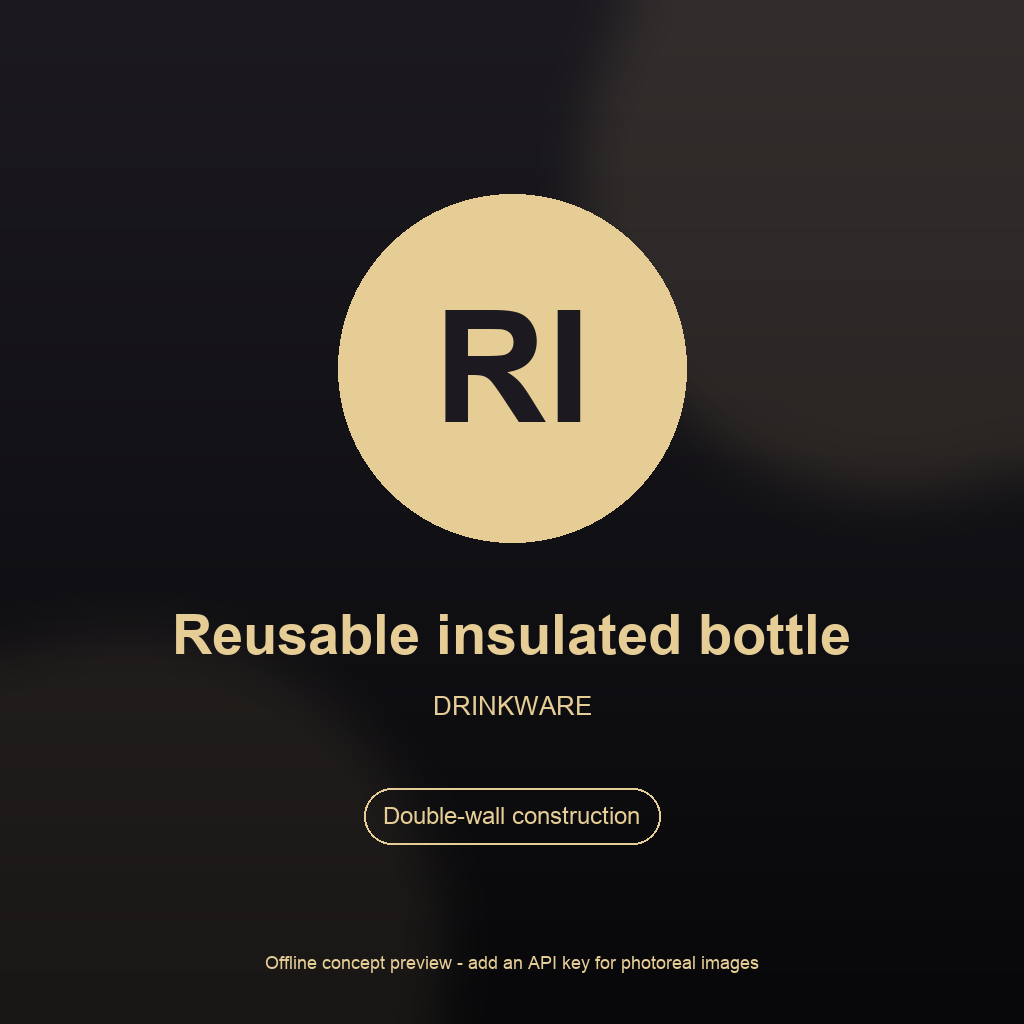

Review flag: generated images are illustrations - compare against the real product before publishing.


In [30]:
png, img_prompt = text_to_image(bottle, style="luxury_dark")
print("Prompt:", img_prompt)
display(IPImage(png, width=360))
print("Review flag: generated images are illustrations - compare against the real product before publishing.")

### Mode 3 · Image → Text
We draw a simple synthetic product photo so the notebook has no external files. Replace `photo_bytes` with `open('your_photo.jpg','rb').read()` to try your own.

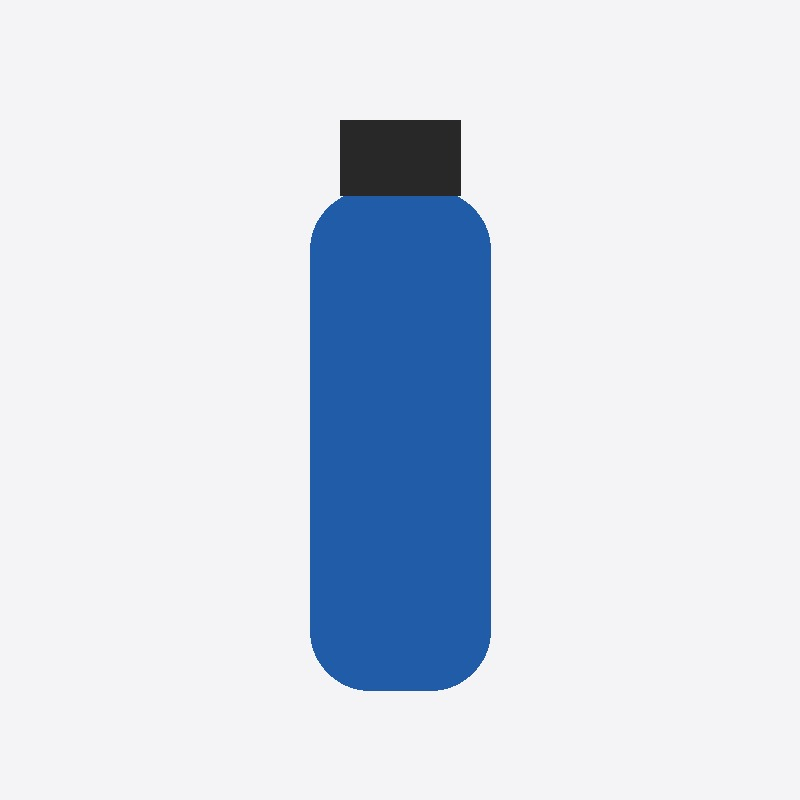

Visual analysis: {'width': 800, 'height': 800, 'orientation': 'square', 'dominant_colours': ['blue'], 'background': 'plain white', 'brightness': 0.86}


### Blue drinkware | water bottle
A well-made blue drinkware. Shown in blue tones, photographed on a plain white background (square shot). A practical choice if you are looking for a water bottle.

- Drinkware - add features to strengthen this listing.

**Meta:** Water bottle: Blue drinkware.

**Review flags**
- ⚠ Offline mode: only colours and composition were read from the photo. Product type, material and size are NOT verified.
- ⚠ Product name was guessed from colour - replace it with the real name.
- ⚠ Size / capacity was not supplied. Do not add it.
- ⚠ Material was not supplied. Do not state one.
- ⚠ No features supplied - bullets may be thin.

In [31]:
photo = Image.new("RGB", (800, 800), (244, 244, 246))
d = ImageDraw.Draw(photo)
d.rounded_rectangle([310, 190, 490, 690], 60, fill=(32, 92, 168))
d.rectangle([340, 120, 460, 195], fill=(40, 40, 40))
buf = io.BytesIO(); photo.save(buf, "JPEG", quality=92); photo_bytes = buf.getvalue()
display(IPImage(photo_bytes, width=220))

draft_img, visual = image_to_text(photo_bytes, ProductFacts(category="Drinkware", keyword="water bottle"))
print("Visual analysis:", visual)
show_draft(draft_img)

### Mode 4 · Image → Image - every style

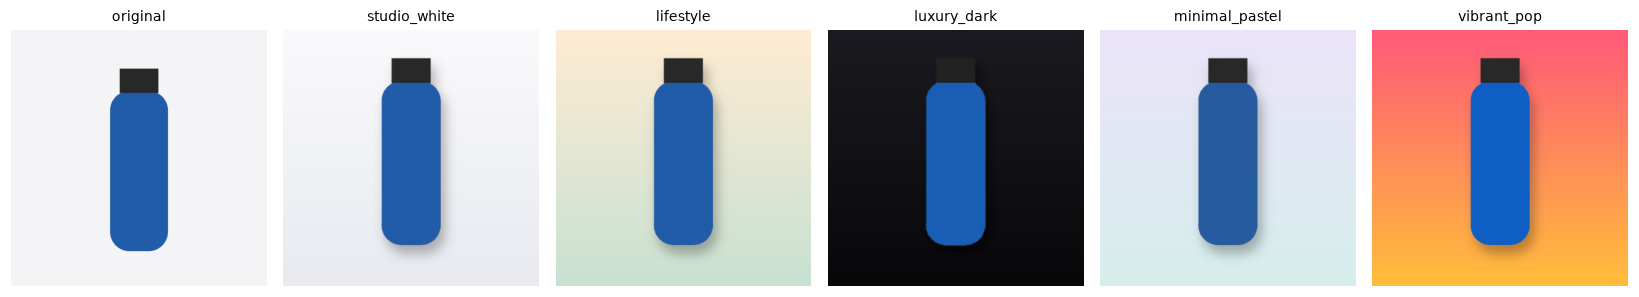

In [32]:
fig, axes = plt.subplots(1, len(IMAGE_STYLES) + 1, figsize=(15, 3.2))
axes[0].imshow(photo); axes[0].set_title("original", fontsize=9)
for ax, style in zip(axes[1:], IMAGE_STYLES):
    out = image_to_image(photo_bytes, style)
    ax.imshow(Image.open(io.BytesIO(out))); ax.set_title(style, fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### Export - matches the seller's next step

In [33]:
for fmt in OUTPUT_FORMATS:
    content, mime, ext = export_draft(draft, fmt, bottle.product_name)
    print(f"──── {fmt.upper()}  ({mime}, .{ext})"); print(content)

──── PLAIN  (text/plain, .txt)
Stainless steel reusable insulated bottle

A reusable insulated bottle made from stainless steel with double-wall construction.

• Double-wall construction for everyday use.
• Made from stainless steel.

Meta: Reusable insulated bottle made from stainless steel with double-wall construction.
──── HTML  (text/html, .html)
<meta name="description" content="Reusable insulated bottle made from stainless steel with double-wall construction.">
<article class="product-listing">
  <h1>Stainless steel reusable insulated bottle</h1>
  <p>A reusable insulated bottle made from stainless steel with double-wall construction.</p>
  <ul>
    <li>Double-wall construction for everyday use.</li>
    <li>Made from stainless steel.</li>
  </ul>
</article>

──── JSON  (application/json, .json)
{
  "title": "Stainless steel reusable insulated bottle",
  "description": "A reusable insulated bottle made from stainless steel with double-wall construction.",
  "bullets": [
    "Dou

## 12 · MongoDB storage

| Collection | Contents |
|---|---|
| `generations` | mode, provider, model, inputs, output, image ids, human review |
| `images` | uploaded and generated PNGs (BSON Binary) |
| `voices` | saved brand voices |
| `request_logs` | mode, provider, latency, status - **no product data** |

Start MongoDB locally (`brew services start mongodb-community` or `docker run -p 27017:27017 mongo`) or point `MONGO_URI`
at MongoDB Atlas. Without a server, the in-memory fallback is used.

In [34]:
"""MongoDB storage layer.

Collections
-----------
generations   one document per request (mode, inputs, output draft, image ids, review, latency)
images        uploaded and generated images (PNG bytes stored as BSON Binary, < 16 MB each)
voices        saved brand voices (rules + example)
request_logs  minimal operational log: mode, provider, latency, status. No product data (slide 7/15).

If MongoDB is unreachable and ALLOW_MEMORY_FALLBACK=true, an in-memory mongomock
database is used so the app still starts. The UI shows which one is active.
"""

import datetime as dt
from typing import Any, Dict, List, Optional

from bson import Binary, ObjectId
from pymongo import DESCENDING, MongoClient
from pymongo.errors import PyMongoError



def now() -> dt.datetime:
    return dt.datetime.now(dt.timezone.utc)


class Store:
    def __init__(self, settings: Settings):
        self.settings = settings
        self.backend = "mongodb"
        try:
            client = MongoClient(settings.mongo_uri, serverSelectionTimeoutMS=1500)
            client.admin.command("ping")
            self.client = client
        except PyMongoError:
            if not settings.allow_memory_fallback:
                raise
            import mongomock  # imported lazily: only needed for the fallback

            self.client = mongomock.MongoClient()
            self.backend = "memory (mongomock fallback)"
        self.db = self.client[settings.mongo_db]
        self.generations = self.db["generations"]
        self.images = self.db["images"]
        self.voices = self.db["voices"]
        self.logs = self.db["request_logs"]
        self._indexes()

    def _indexes(self) -> None:
        try:
            self.generations.create_index([("created_at", DESCENDING)])
            self.generations.create_index("mode")
            self.logs.create_index([("created_at", DESCENDING)])
            self.voices.create_index("name", unique=True)
        except Exception:
            pass

    # ------------------------------------------------------------ images
    def save_image(self, png: bytes, kind: str) -> str:
        res = self.images.insert_one({"data": Binary(png), "mime": "image/png", "kind": kind,
                                      "size": len(png), "created_at": now()})
        return str(res.inserted_id)

    def get_image(self, image_id: str) -> Optional[bytes]:
        try:
            doc = self.images.find_one({"_id": ObjectId(image_id)})
        except Exception:
            return None
        return bytes(doc["data"]) if doc else None

    # ------------------------------------------------------------ generations
    def save_generation(self, doc: Dict[str, Any]) -> str:
        doc = dict(doc)
        doc["created_at"] = now()
        doc.setdefault("review", None)
        if not self.settings.store_inputs:
            doc["input"] = {"redacted": True}
        return str(self.generations.insert_one(doc).inserted_id)

    def list_generations(self, mode: Optional[str] = None, limit: int = 50) -> List[dict]:
        q = {"mode": mode} if mode else {}
        cur = self.generations.find(q).sort("created_at", DESCENDING).limit(limit)
        return [self._public(d) for d in cur]

    def get_generation(self, gid: str) -> Optional[dict]:
        try:
            d = self.generations.find_one({"_id": ObjectId(gid)})
        except Exception:
            return None
        return self._public(d) if d else None

    def review_generation(self, gid: str, review: dict) -> bool:
        update: Dict[str, Any] = {"review": {**review, "reviewed_at": now()}}
        if review.get("edited"):
            update["final_output"] = review["edited"]
        try:
            res = self.generations.update_one({"_id": ObjectId(gid)}, {"$set": update})
        except Exception:
            return False
        return res.matched_count == 1

    def delete_generation(self, gid: str) -> bool:
        try:
            d = self.generations.find_one({"_id": ObjectId(gid)})
        except Exception:
            return False
        if not d:
            return False
        for iid in d.get("image_ids", []):
            try:
                self.images.delete_one({"_id": ObjectId(iid)})
            except Exception:
                pass
        self.generations.delete_one({"_id": d["_id"]})
        return True

    @staticmethod
    def _public(d: dict) -> dict:
        d = dict(d)
        d["id"] = str(d.pop("_id"))
        if isinstance(d.get("created_at"), dt.datetime):
            d["created_at"] = d["created_at"].isoformat()
        r = d.get("review")
        if r and isinstance(r.get("reviewed_at"), dt.datetime):
            r["reviewed_at"] = r["reviewed_at"].isoformat()
        return d

    # ------------------------------------------------------------ voices
    def list_voices(self) -> List[dict]:
        out = []
        for v in self.voices.find().sort("name", 1):
            v["id"] = str(v.pop("_id"))
            v.pop("created_at", None)
            out.append(v)
        return out

    def get_voice(self, vid: Optional[str]) -> Optional[dict]:
        if not vid:
            return None
        try:
            return self.voices.find_one({"_id": ObjectId(vid)})
        except Exception:
            return None

    def save_voice(self, voice: dict) -> str:
        res = self.voices.update_one({"name": voice["name"]}, {"$set": {**voice, "created_at": now()}}, upsert=True)
        if res.upserted_id:
            return str(res.upserted_id)
        return str(self.voices.find_one({"name": voice["name"]})["_id"])

    def delete_voice(self, vid: str) -> bool:
        try:
            return self.voices.delete_one({"_id": ObjectId(vid)}).deleted_count == 1
        except Exception:
            return False

    # ------------------------------------------------------------ logs + metrics
    def log_request(self, mode: str, provider: str, latency_ms: float, status: str, error_code: str = "") -> None:
        self.logs.insert_one({"mode": mode, "provider": provider, "latency_ms": round(latency_ms, 1),
                              "status": status, "error_code": error_code, "created_at": now()})

    def metrics(self) -> dict:
        """Evaluation metrics from slide 13, computed from stored logs and reviews."""
        logs = list(self.logs.find({}, {"_id": 0}))
        gens = list(self.generations.find({}, {"mode": 1, "review": 1, "output": 1}))

        def pct(vals: List[float], p: float) -> Optional[float]:
            if not vals:
                return None
            s = sorted(vals)
            k = max(0, min(len(s) - 1, int(round(p * (len(s) - 1)))))
            return round(s[k], 1)

        by_mode: Dict[str, dict] = {}
        for m in ["text-to-text", "text-to-image", "image-to-text", "image-to-image"]:
            ml = [l for l in logs if l["mode"] == m]
            ok = [l["latency_ms"] for l in ml if l["status"] == "ok"]
            by_mode[m] = {
                "requests": len(ml),
                "errors": sum(1 for l in ml if l["status"] != "ok"),
                "p50_ms": pct(ok, 0.5),
                "p95_ms": pct(ok, 0.95),
            }
        reviewed = [g["review"] for g in gens if g.get("review")]
        approved = [r for r in reviewed if r.get("approved")]
        ratings = [r["rating"] for r in reviewed if r.get("rating")]
        secs = [r["seconds_to_approve"] for r in approved if r.get("seconds_to_approve") is not None]
        unsupported = sum(r.get("unsupported_claims", 0) for r in reviewed)
        total_claims = sum(r.get("total_claims", 0) for r in reviewed)
        ok_all = [l["latency_ms"] for l in logs if l["status"] == "ok"]
        flags_auto = [len((g.get("output") or {}).get("review_flags", [])) for g in gens if g.get("output")]
        return {
            "total_requests": len(logs),
            "error_rate": round(sum(1 for l in logs if l["status"] != "ok") / len(logs), 3) if logs else None,
            "p50_ms": pct(ok_all, 0.5),
            "p95_ms": pct(ok_all, 0.95),
            "share_under_3s": round(sum(1 for v in ok_all if v < 3000) / len(ok_all), 3) if ok_all else None,
            "generations": len(gens),
            "reviewed": len(reviewed),
            "approved": len(approved),
            "approval_rate": round(len(approved) / len(reviewed), 3) if reviewed else None,
            "avg_rating": round(sum(ratings) / len(ratings), 2) if ratings else None,
            "avg_seconds_per_approved": round(sum(secs) / len(secs), 1) if secs else None,
            "unsupported_claim_rate": round(unsupported / total_claims, 3) if total_claims else None,
            "avg_auto_flags": round(sum(flags_auto) / len(flags_auto), 2) if flags_auto else None,
            "by_mode": by_mode,
            "db_backend": self.backend,
        }

In [35]:
store = Store(settings)
print("Database backend:", store.backend)

# save the slide-12 run, the images and a brand voice
gid = store.save_generation({"mode": "text-to-text", "provider": settings.resolve_provider(None), "model": "notebook",
                             "input": normalize_facts(bottle).model_dump(), "output": draft.model_dump(), "image_ids": []})
img_id = store.save_image(png, "generated")
store.save_generation({"mode": "text-to-image", "provider": settings.resolve_provider(None), "model": "notebook",
                       "input": bottle.model_dump(), "output": {"image_id": img_id, "prompt": img_prompt}, "image_ids": [img_id]})
vid = store.save_voice({"name": "Nordic calm", "base_tone": "minimal",
                        "rules": "Short sentences. No exclamation marks. Mention care last.", "example": ""})
for r in RUN_LOG:
    store.log_request(r["mode"], r["provider"], r["latency_ms"], r["status"], r["error_code"])

print({c: store.db[c].count_documents({}) for c in ["generations", "images", "voices", "request_logs"]})
pd.DataFrame(store.list_generations())[["id", "mode", "provider", "created_at"]]

Database backend: memory (mongomock fallback)
{'generations': 2, 'images': 1, 'voices': 1, 'request_logs': 13}


,id,mode,provider,created_at
0,6af918daf9c15058d96a19df,text-to-text,mock,2026-11-15T02:28:42.318000
1,6af918daf9c15058d96a19e1,text-to-image,mock,2026-11-15T02:28:42.318000


In [36]:
# A saved voice changes style, never facts
voice = store.get_voice(vid)
show_draft(text_to_text(bottle.model_copy(update={"brand_voice": "minimal"}), voice=voice))
print(build_prompt(normalize_facts(bottle), voice)["user"].split("Target keyword")[0][-260:])

### Stainless steel reusable insulated bottle
Reusable insulated bottle. Stainless steel. Double-wall construction.

- Double-wall construction.
- Made from stainless steel.

**Meta:** Reusable insulated bottle made from stainless steel with double-wall construction.

**Review flags**
- ⚠ Size / capacity was not supplied. Do not add it.

n
- Target audience: (not supplied)
- Use case: (not supplied)
- Extra notes: (not supplied)

Brand voice: clear and practical - Plain language focused on everyday use.
Saved brand voice 'Nordic calm': Short sentences. No exclamation marks. Mention care last.



## 13 · Evaluation: measure usefulness before claiming impact (slide 13)

| Question | Measure | How to evaluate |
|---|---|---|
| Did it save time? | Seconds per approved listing | Compare manual and assisted tasks on the same product set |
| Are facts accurate? | Unsupported claim rate | Review each generated claim against source product data |
| Is the copy usable? | Human quality rating | Blind reviewer scores clarity, completeness, voice |
| Does the interface work? | Task completion / error rate | Observe sellers completing input, review, export |
| Does it help search? | Search performance over time | Test live pages; separate copy from technical SEO changes |

Below we run a small **illustrative** test set (invented products) through the pipeline and compute the automatic measures.
Human measures (rating, unsupported claims, time to approve) must come from real reviewers - a template is provided.

In [37]:
test_set = [
    ProductFacts(product_name="Reusable insulated bottle", category="Drinkware", materials="Stainless steel",
                 features=["Double-wall construction"], brand_voice="clear and practical", keyword="insulated bottle"),
    ProductFacts(product_name="Bamboo cutting board", category="Home & Kitchen", materials="Bamboo", size="45 x 30 cm",
                 features=["Juice groove", "Hanging hole"], brand_voice="professional", keyword="bamboo chopping board"),
    ProductFacts(product_name="Wireless earbuds", category="Electronics", features=["Bluetooth 5.3", "Charging case", "Touch controls"],
                 target_audience="commuters", brand_voice="playful", keyword="wireless earbuds"),
    ProductFacts(product_name="Linen cushion cover", category="Home decor", materials="Linen", size="45 x 45 cm",
                 features=["Hidden zip"], brand_voice="luxury", keyword="linen cushion cover"),
    ProductFacts(product_name="Yoga mat", category="Sports & Outdoors", materials="TPE", size="183 x 61 cm, 6 mm thick",
                 features=["Textured non-slip surface", "Carry strap"], brand_voice="minimal"),
    ProductFacts(product_name="Stoneware coffee mug", category="Drinkware", materials="Stoneware", size="350 ml",
                 features=["Reactive glaze", "Wide handle"], brand_voice="luxury", keyword="handmade mug"),
    ProductFacts(product_name="Kids rain jacket", category="Apparel", materials="Polyester",
                 features=["Hood", "Reflective strips"], target_audience="children aged 4-8", brand_voice="playful"),
    ProductFacts(product_name="LED desk lamp", category="Lighting", materials="Aluminium",
                 features=["Adjustable arm", "USB-C power", "Three brightness levels"], brand_voice="minimal", keyword="desk lamp"),
]

rows = []
for f in test_set:
    t0 = time.perf_counter()
    d = text_to_text(f)
    ms = (time.perf_counter() - t0) * 1000
    text = " ".join([d.title, d.description, *d.bullets]).lower()
    rows.append({
        "product": f.product_name, "tone": f.brand_voice, "latency_ms": round(ms, 1),
        "review_flags": len(d.review_flags),
        "unsupported_auto": sum("Unsupported" in x or "not supported" in x for x in d.review_flags),
        "keyword_uses": text.count(f.keyword.lower()) if f.keyword else None,
        "title_len": len(d.title), "meta_len": len(d.meta_description), "bullets": len(d.bullets),
    })
results = pd.DataFrame(rows)
display(results)
print(f"Median latency {results.latency_ms.median():.1f} ms · auto-detected unsupported claims: {results.unsupported_auto.sum()} · "
      f"meta descriptions within 160 chars: {(results.meta_len <= 160).mean():.0%}")

,product,tone,latency_ms,review_flags,unsupported_auto,keyword_uses,title_len,meta_len,bullets
0,Reusable insulated bottle,clear and practical,0.2,1,0,2.0,41,82,2
1,Bamboo cutting board,professional,0.1,0,0,2.0,44,79,4
2,Wireless earbuds,playful,0.1,2,0,2.0,16,70,3
3,Linen cushion cover,luxury,0.1,0,0,2.0,19,36,3
4,Yoga mat,minimal,0.1,0,0,NaN,12,70,4
5,Stoneware coffee mug,luxury,0.1,0,0,2.0,35,71,4
6,Kids rain jacket,playful,0.1,1,0,NaN,26,69,3
7,LED desk lamp,minimal,0.1,1,0,2.0,23,95,4


Median latency 0.1 ms · auto-detected unsupported claims: 0 · meta descriptions within 160 chars: 100%


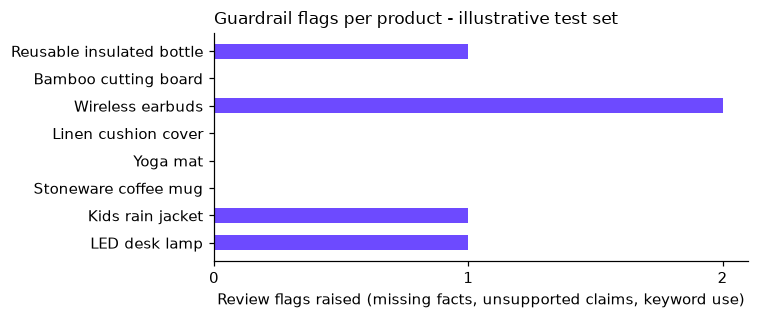

In [38]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results["product"], results["review_flags"], color="#6d4aff", height=0.55)
ax.invert_yaxis(); ax.set_xlabel("Review flags raised (missing facts, unsupported claims, keyword use)")
ax.set_title("Guardrail flags per product - illustrative test set", loc="left", fontsize=11)
ax.xaxis.get_major_locator().set_params(integer=True)
plt.tight_layout(); plt.show()

**Human review template** - fill this with real reviewer data (blind scoring). The numbers are *not* pre-filled on purpose: inventing them would contradict slide 14.

In [39]:
review_template = pd.DataFrame({
    "product": results["product"],
    "manual_seconds": pd.NA,           # time to write the listing by hand
    "assisted_seconds": pd.NA,         # time from draft shown to approval (the web app records this)
    "claims_checked": pd.NA,
    "unsupported_claims": pd.NA,
    "rating_1_to_5": pd.NA,            # clarity, completeness, voice
})
review_template.to_csv("human_review_template.csv", index=False)
display(review_template.head(3))


def summarise_review(df: pd.DataFrame) -> dict:
    df = df.dropna()
    if df.empty:
        return {"status": "no reviewer data yet"}
    return {
        "time_saving_%": round(100 * (1 - df.assisted_seconds.sum() / df.manual_seconds.sum()), 1),
        "speed_up_x": round(df.manual_seconds.sum() / df.assisted_seconds.sum(), 1),
        "unsupported_claim_rate": round(df.unsupported_claims.sum() / df.claims_checked.sum(), 3),
        "mean_rating": round(df.rating_1_to_5.mean(), 2), "n": len(df),
    }

print(summarise_review(review_template))
print("Metrics from MongoDB:", {k: v for k, v in store.metrics().items() if k != "by_mode"})

,product,manual_seconds,assisted_seconds,claims_checked,unsupported_claims,rating_1_to_5
0,Reusable insulated bottle,<NA>,<NA>,<NA>,<NA>,<NA>
1,Bamboo cutting board,<NA>,<NA>,<NA>,<NA>,<NA>
2,Wireless earbuds,<NA>,<NA>,<NA>,<NA>,<NA>


{'status': 'no reviewer data yet'}
Metrics from MongoDB: {'total_requests': 13, 'error_rate': 0.0, 'p50_ms': 33.5, 'p95_ms': 611.6, 'share_under_3s': 1.0, 'generations': 2, 'reviewed': 0, 'approved': 0, 'approval_rate': None, 'avg_rating': None, 'avg_seconds_per_approved': None, 'unsupported_claim_rate': None, 'avg_auto_flags': 0.5, 'db_backend': 'memory (mongomock fallback)'}


## 14 · What the source claims, and what the evidence supports (slide 14)

| Source claim | What we can say now | What to verify |
|---|---|---|
| “Under 3 seconds” generation | Unmeasured response-time target | Record latency across models and request sizes |
| 30 min → under 30 sec; “95%” reduction | Source estimates conflict mathematically | Time matched tasks; clarify what is included |
| “10× faster” catalog updates | No workflow benchmark supplied | Measure batch size and approval time |
| “High-converting” copy | No conversion study supplied | Run controlled experiment and report sample size |

In [40]:
manual_s, assisted_s = 30 * 60, 30
print(f"30 min -> 30 s is {manual_s / assisted_s:.0f}x faster, a {100 * (1 - assisted_s / manual_s):.1f}% reduction (not 95%).")
print(f"A 95% reduction from 30 min would leave {manual_s * 0.05 / 60:.1f} min, i.e. {manual_s * 0.05:.0f} s - not 30 s.")

ok = [r["latency_ms"] for r in RUN_LOG if r["status"] == "ok"]
print(f"\nMeasured in this notebook ({settings.resolve_provider(None)} provider): {len(ok)} requests, "
      f"median {pd.Series(ok).median():.1f} ms, {(pd.Series(ok) < 3000).mean():.0%} under 3 s.")
print("Note: offline-template latency says nothing about a real LLM. Re-run with an API key and report model, request size and sample size.")

30 min -> 30 s is 60x faster, a 98.3% reduction (not 95%).
A 95% reduction from 30 min would leave 1.5 min, i.e. 90 s - not 30 s.

Measured in this notebook (mock provider): 22 requests, median 0.1 ms, 100% under 3 s.
Note: offline-template latency says nothing about a real LLM. Re-run with an API key and report model, request size and sample size.


## 15 · Limitations and safeguards (slide 15) - demonstrated

| Limitation | Practical safeguard | Where in this project |
|---|---|---|
| Model may invent or overstate a benefit | Generate from supplied facts; flag and review claims | fact-only prompt, `find_unsupported_claims`, review gate |
| SEO wording cannot guarantee rank or traffic | Accurate content, measure real outcomes | `keyword_flags`; evaluation §13 |
| Provider latency, outages, or cost can vary | Timeouts, retries with limits, usage monitoring | `_post`, rate limiter, `request_logs` |
| Tone may sound generic or inconsistent | Brand examples, saved voice rules, human editing | `voices` collection |
| Export may not match every storefront schema | Test destination formats, validate fields | `export_draft` |
| Product data can be sensitive or proprietary | Minimise retained data, access controls | `STORE_INPUTS`, delete endpoint, logs without product data |
| **Generated images are illustrations** | Flag every image; compare to the real item | Text → Image flag |
| **Image → Text can misread photos** | Only visible details; material/size “not verified” | vision prompt + flags |
| **Image → Image may alter the product** | Prompt locks shape/colour/labels; reviewer confirms | edit prompt + review checkbox |

**a) Invented benefits are flagged** (shown in §9). **b) Missing facts are never guessed:**

In [41]:
sparse = text_to_text(ProductFacts(product_name="Canvas tote bag", category="Bags"))
show_draft(sparse)

### Canvas tote bag
The canvas tote bag, from our bags range.

- Bags - add features to strengthen this listing.

**Meta:** Canvas tote bag.

**Review flags**
- ⚠ Size / capacity was not supplied. Do not add it.
- ⚠ Material was not supplied. Do not state one.
- ⚠ No features supplied - bullets may be thin.

**c) Provider timeouts → bounded retries and a safe message.** We simulate a provider that always times out:

In [42]:
from unittest import mock

calls = {"n": 0}
def always_timeout(*a, **k):
    calls["n"] += 1
    raise httpx.TimeoutException("simulated")

fast = Settings(); fast.max_retries = 2
with mock.patch.object(httpx.Client, "post", always_timeout), mock.patch.object(time, "sleep", lambda s: None):
    try:
        _post(fast, "https://example.invalid", headers={}, json_body={})
    except ProviderError as e:
        print(f"Attempts: {calls['n']} (1 + {fast.max_retries} retries) -> code={e.code!r}, message={e.message!r}")

Attempts: 3 (1 + 2 retries) -> code='timeout', message='The AI provider took too long to respond. Please retry.'


**d) Schema validation checks structure, not truth** - this passes the schema yet contains a false claim; only the guardrail and the human reviewer catch it:

In [43]:
looks_fine = check_response({"title": "Insulated bottle", "description": "Keeps drinks hot for 12 hours.",
                             "bullets": ["Double-wall construction"], "meta_description": "Bottle", "review_flags": []})
print("Schema check passed:", isinstance(looks_fine, ListingDraft))
print("Guardrail:", finalize(looks_fine, example_facts).review_flags)

Schema check passed: True
Guardrail: ['Size / capacity was not supplied. Do not add it.', "Unsupported number '12 hours' is not in the product facts - verify or remove.", "Claim 'keeps drinks' is not supported by the supplied facts - verify or remove.", "Claim '12 hours' is not supported by the supplied facts - verify or remove."]


**e) Bad uploads are rejected safely:**

In [44]:
for label, data in [("text file", b"hello"), ("empty", b""), ("too large", b"0" * int(9 * 1024 * 1024))]:
    try:
        load_image(data, max_mb=8)
    except ImageProblem as e:
        print(f"{label:10s} -> {e}")

text file  -> File is not a readable image (use PNG, JPG or WEBP).
empty      -> No image was uploaded.
too large  -> Image is larger than 8 MB.


**f) Data minimisation:** deleting a generation also deletes its images.

In [45]:
before = store.images.count_documents({})
gens = store.list_generations(mode="text-to-image")
store.delete_generation(gens[0]["id"])
print("images before/after delete:", before, "->", store.images.count_documents({}))

images before/after delete: 1 -> 0


## 16 · Five-day build plan (slide 11)

| Day | Goal | Delivered in this project |
|---|---|---|
| Day 1 | Working form - fields, test API request, one basic result | `frontend/`, `/api/generate/text-to-text` |
| Day 2 | Prompt design - output fields, tone rules, examples exposing unsupported claims | §8, §9 |
| Day 3 | SEO + formatting - keyword guidance, export formats | `keyword_flags`, `export_draft` |
| Days 4–5 | Review + export - representative products, error tests, copy/export, polish | §13, §15, review gate in the UI, `tests/` |

Source estimate: 3–5 calendar days, about 15 development hours. Team size and delivery scope were not specified.

## 17 · Next steps and conclusion (slide 16)

1. Build the smallest usable flow with fact-first prompts and a reviewable schema. ✅
2. Test output quality and time savings on a representative catalogue sample. → use §13 with real reviewers.
3. Add saved brand voices ✅, batch editing (prototype below) and direct store integrations only after validation.

In [46]:
# Batch prototype: catalogue CSV in -> drafts CSV out (every row still needs human review)
catalogue = pd.DataFrame([f.model_dump() for f in test_set])
catalogue["features"] = catalogue["features"].apply(lambda x: "; ".join(x))
catalogue.to_csv("sample_catalogue.csv", index=False)

def batch_generate(path_in: str, path_out: str) -> pd.DataFrame:
    out = []
    for row in pd.read_csv(path_in).fillna("").to_dict("records"):
        row["features"] = [x.strip() for x in str(row["features"]).split(";") if x.strip()]
        row["brand_voice_id"] = None
        try:
            d = text_to_text(ProductFacts(**row))
            out.append({"product_name": row["product_name"], **d.model_dump(), "status": "needs review"})
        except (InputProblem, ProviderError, ResponseProblem) as e:
            out.append({"product_name": row["product_name"], "status": f"error: {e}"})
    df = pd.DataFrame(out); df.to_csv(path_out, index=False)
    return df

batch_generate("sample_catalogue.csv", "sample_drafts.csv")[["product_name", "title", "status"]]

/var/folders/yv/rbk6mmh56511tfxt4r82_86c0000gn/T/ipykernel_22393/4060902055.py:8: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  for row in pd.read_csv(path_in).fillna("").to_dict("records"):


,product_name,title,status
0,Reusable insulated bottle,Stainless steel reusable insulated bottle,needs review
1,Bamboo cutting board,Bamboo cutting board | bamboo chopping board,needs review
2,Wireless earbuds,Wireless earbuds,needs review
3,Linen cushion cover,Linen cushion cover,needs review
4,Yoga mat,Tpe yoga mat,needs review
5,Stoneware coffee mug,Stoneware coffee mug | handmade mug,needs review
6,Kids rain jacket,Polyester kids rain jacket,needs review
7,LED desk lamp,Aluminium led desk lamp,needs review


> ### Conclusion
> **Automate the repetitive draft. Keep product truth and publication decisions with the seller.**

## 18 · References (slide 17)

1. OpenAI API, Structured Outputs - https://platform.openai.com/docs/guides/structured-outputs
2. Google AI for Developers, Gemini structured outputs - https://ai.google.dev/gemini-api/docs/generate-content/structured-output
3. Streamlit documentation, Secrets management - https://docs.streamlit.io/develop/concepts/connections/secrets-management
4. Google Search Central, Developer guide - https://developers.google.com/search/docs/fundamentals/get-started-developers
5. Google Search Central, Share product data with Google - https://developers.google.com/search/docs/specialty/ecommerce/share-your-product-data-with-google

## 19 · Using the running web app's REST API

Start the backend from the project root: `uvicorn backend.main:app --port 8000`, open http://localhost:8000, then run this cell.

In [47]:
API = "http://localhost:8000"
try:
    print(httpx.get(f"{API}/api/health", timeout=3).json())
    r = httpx.post(f"{API}/api/generate/text-to-text", json=bottle.model_dump(), timeout=60).json()
    print(json.dumps(r["draft"], indent=2))
    r = httpx.post(f"{API}/api/generate/image-to-image", files={"image": ("p.jpg", photo_bytes, "image/jpeg")},
                   data={"style": "studio_white"}, timeout=120).json()
    display(IPImage(httpx.get(API + r["image_url"]).content, width=240))
except httpx.HTTPError:
    print("Backend not running - start it with: uvicorn backend.main:app --port 8000")

Backend not running - start it with: uvicorn backend.main:app --port 8000
